In [6]:
import numpy as np
import scipy as sp
import matplotlib.pyplot as plt
import CoolProp.CoolProp as CP
import thermo as thermo
import time as timer
import cProfile
import pstats
import yaml
import copy
import sys

Fluid Property functions

In [116]:
def Sn_rho(temp):
    #return liquid Tin density, Stankus
    return 6982.2 - 0.75643 * (temp - 505) + 1.074e-4 * (temp - 505) ** 2 - 2.194e-8 * (temp - 505) ** 3

def Sn_tcx(temp):
    #return liquid Tin thermal conductivity [W/mK] fix this one?
    return 13.9 + 0.02868 * temp

def Sn_mu(temp):
    #return liquid Tin viscosity [Pas]
    return 3.908e-4 * np.exp(790.7 / temp)

def Sn_cp(temp):
    #return liquid Tin cp [J/kgK]
    #set constant cp for now, need to tract enthalpy instead of temp if using varying cp
    return 300
    #return 182.7 + 0.05177 * temp + 1.086e7 * temp ** (-2)
    
def gr_cp(temp):
    #return graphite CP, from Entegris [J/kgK]
    return (0.44391 + 0.30795e-4 * temp - 0.61257e5 * temp ** (-2) + 0.10795e8 * temp ** (-3)) * 4184

def gr_rho(temp):
    #return graphite density [kg/m^3] fix
    return 1860

def gr_emis(temp: float) -> float:
    """
    Calculate the emissivity of graphite as a function of temperature.
    
    Parameters:
    temp (float): Temperature (K).
    
    Returns:
    float: Emissivity of graphite.
    """
    #return 0.679 + 6e-5 * temp
    return 0.6

def w_emis_spectral(temperature: float, wavelength: float) -> float:
    """
    Calculate the emissivity of tungsten as a function of temperature and wavelength.
    
    Parameters:
    temperature (float): Temperature (K).
    wavelength(float): wavelength (micron)
    
    Returns:
    float: Emissivity of tungsten.
    """
    et = [
        [0, 0.0, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 1, 1.5, 2, 2.5, 3, 3.5, 4, 4.5, 5, 100],
        [0, 0.539, 0.539, 0.539, 0.541, 0.542, 0.54, 0.533, 0.508, 0.497, 0.486, 0.474, 0.463, 0.452, 0.441, 
         0.43, 0.419, 0.262, 0.141, 0.101, 0.082, 0.069, 0.062, 0.056, 0.05, 0.05],
        [700, 0.539, 0.539, 0.539, 0.541, 0.542, 0.54, 0.533, 0.508, 0.497, 0.486, 0.474, 0.463, 0.452, 0.441, 
         0.43, 0.419, 0.262, 0.141, 0.101, 0.082, 0.069, 0.062, 0.056, 0.05, 0.05],
        [1600, 0.557, 0.557, 0.573, 0.578, 0.564, 0.546, 0.532, 0.507, 0.495, 0.485, 0.474, 0.462, 0.451, 0.44, 
         0.429, 0.417, 0.299, 0.219, 0.171, 0.137, 0.114, 0.096, 0.08, 0.071, 0.071],
        [2600, 0.383, 0.383, 0.453, 0.465, 0.467, 0.466, 0.461, 0.448, 0.44, 0.433, 0.425, 0.417, 0.409, 0.4, 0.39,
         0.383, 0.314, 0.265, 0.23, 0.211, 0.197, 0.187, 0.183, 0.183, 0.183],
        [3100, 0.41, 0.41, 0.456, 0.461, 0.46, 0.456, 0.451, 0.436, 0.428, 0.42, 0.413, 0.405, 0.398, 0.39, 0.384, 
         0.378, 0.32, 0.291, 0.276, 0.26, 0.25, 0.24, 0.24, 0.24, 0.24]
    ]
    temperatures = np.array([row[0] for row in et[1:]])
    wavelengths = np.array(et[0][1:])
    ev = np.array([row[1:] for row in et[1:]])
    # Check if the temperature and wavelength are within the table's range
    if not (min(temperatures) <= temperature <= max(temperatures)):
        print("temp:", temperature)
        raise ValueError("Temperature out of range.")
    if not (min(wavelengths) <= wavelength <= max(wavelengths)):
        raise ValueError("Wavelength out of range.")

    # Perform bilinear interpolation
    temp_idx = np.searchsorted(temperatures, temperature) - 1
    wl_idx = np.searchsorted(wavelengths, wavelength) - 1

    T1, T2 = temperatures[temp_idx], temperatures[temp_idx + 1]
    WL1, WL2 = wavelengths[wl_idx], wavelengths[wl_idx + 1]
    Q11 = ev[temp_idx, wl_idx]
    Q12 = ev[temp_idx, wl_idx + 1]
    Q21 = ev[temp_idx + 1, wl_idx]
    Q22 = ev[temp_idx + 1, wl_idx + 1]

    interpolated_emissivity = (
        Q11 * (T2 - temperature) * (WL2 - wavelength) +
        Q21 * (temperature - T1) * (WL2 - wavelength) +
        Q12 * (T2 - temperature) * (wavelength - WL1) +
        Q22 * (temperature - T1) * (wavelength - WL1)
    ) / ((T2 - T1) * (WL2 - WL1))
    
    return interpolated_emissivity

def gr_tcx(temp: float) -> float:
    """
    Calculate the thermal conductivity of graphite as a function of temperature.
    
    Parameters:
    temp (float): Temperature (K).
    
    Returns:
    float: Thermal conductivity of graphite (W/mK).
    """
    tcx_arr = np.array([[20,	115],
    [200,	100],
    [400,	85],
    [600,	73],
    [800,	62],
    [1000,	54],
    [1200,	49],
    [1400,	45],
    [1600,	42],
    [1800,	40],
    [2000,	39],
    [2200,	37],
    [2400,	34]]
                     )
    return np.interp(1100,tcx_arr[:,0],tcx_arr[:,1])

def w_tcx(temp: float) -> float:
    """
    Calculate the thermal conductivity of tungsten as a function of temperature.
    
    Parameters:
    temp (float): Temperature (K).
    
    Returns:
    float: Thermal conductivity of tungsten (W/mK).
    """
    # Example function for tungsten thermal conductivity; adjust this based on actual data.
    if temp < 300:
        return 173
    elif temp < 1000:
        return 173 - 0.03 * (temp - 300)
    else:
        return 152 - 0.01 * (temp - 1000)
        
def Sn_Pr (temp):
    #return Prandtl number
    return Sn_cp(temp) * Sn_mu(temp)  / Sn_tcx(temp)

def storage_rho(temp):
    #storage graphite density
    #return 1743
    return 1500

def storage_cp(temp):
    #storage graphite specific heat
    #replaced with fixed cp until better enthalpy handling implemented
    cp_arr= np.array([1.27, 1.92, 1.99, 2.13])
    temp_C = np.array([300, 750, 1200, 1995])
    temp_C = np.append(temp_C,2400)
    cp_arr = np.append(cp_arr, 2.13)
    temp_C_interp = temp - 273.15
    # Extrapolate up to 2400°C
    if temp_C_interp > 2400:
        temp_C_interp = 2400
    return 2000   
    #return np.interp(temp_C_interp, temp_C, cp_arr) * 1000

def storage_tcx(temp):
    #storage graphite conductivity
    temp_C = np.array([300, 750, 1200, 1995])
    conductivity = np.array([31.5, 28.7, 24.8, 23.1])
    temp_C_interp = temp - 273.15
    temp_C = np.append(temp_C,2400)
    conductivity = np.append(conductivity, conductivity[-1] + (conductivity[-1] - conductivity[-2]) / (temp_C[-2] - temp_C[-3]) * (temp_C[-1] - temp_C[-2]))
        # Extrapolate up to 2400°C
    if temp_C_interp > 2400:
        temp_C_interp = 2400
    return 15
    #return np.interp(temp_C_interp, temp_C, conductivity)

def ins_tcx(temp):
    #Carbon insulation thermal conductivity in Argon
    temps = np.array([0, 400, 800, 1000, 2000, 2500])
    tcx = np.array([0.09, 0.09, 0.176, 0.35, 0.94, 0.94 + (0.94 - 0.35) * 500 / 1000]) #data for 1000 and 2000 C from manufacturer. Linear extrapolation to 2500 C, flat down to 0C
    temp_C = temp - 273.15
    return np.interp(temp_C, temps, tcx)

Basic Fluid Flow Functions
Current assumptions:
Fully developed

In [78]:
def CircPipeFF(Re, D_h, rough):
    #return circular pipe friction factor (turbulent: Zigrang and Sylvester)
    if (Re < 2300):
        return 64 / Re
    else:
        return (-2 * np.log10(2 * rough / (7.54 * D_h) - 5.02 / Re * np.log10(2*rough / (7.54 * D_h) + 13 / Re))) ** (-2)

def RectPipeFF(Re, H, W, rough):
    #return recatngular pipe friction factor from Nellis and Klein, eq 5-60 and 5-65
    AR = H / W
    D_h = 2 * H * W / (H + W)
    if (Re < 2300):
        return 96 / Re * (1 - 1.3553 * AR + 1.9467 * AR ** 2 - 1.7012 * AR ** 3 + 0.9564 * AR ** 4 - 0.2537 * AR ** 5)
    else:
        return (-2 * np.log10(2 * rough / (7.54 * D_h) - 5.02 / Re * np.log10(2 * rough / (7.54 * D_h) + 13 / Re))) ** (-2)

def CircPipeNu(Re, ff, Pr):
    #return circular pipe Nusselt number from Nellis and Klein eq 5-76 and Taler 2018
    if (Re < 2300):
        return 4.36
    else:
        return 5.31 + 0.221 * (Re * Pr) ** 0.8174

def RectPipeNu(Re, H, W, ff, Pr):
    #return rectangular pipe Nusselt number
    AR = H / W
    if (Re < 3000):
        return 8.235 * (1 - 2.042 * AR + 3.085 * AR ** 2 -2.477 * AR ** 3 + 1.058 * AR ** 4 - 0.186 * AR ** 5)
    else:
        return 5.31 + 0.221 * (Re * Pr) ** 0.8174

Thermal resistances

In [79]:
def RprimeCondCyl(D_in, D_out, k_wall):
    #def cylindrical wall conduction thermal resistance [K/Wm]
    return np.log(D_out / D_in) / (2 * np.pi * k_wall)

def RCondWall(L, A_c, k_wall):
    #define planar conduction thermal resistance [K/W]
    return L / (k_wall * A_c)

def RprimeConvCyl(Nu, k_fluid, D):
    #define convection thermal resistance for a fluid in a pipe [K/Wm]
    h_bar = Nu * k_fluid / D
    per = np.pi * D
    return 1 / (h_bar * per)

def RConvWall(Nu, L, A_c, k_fluid):
    #def convection thermal resistance on a planar wall [K/W]
    #L is the characteristic length, hydraulic diameter for internal flows
    h_bar = Nu * k_fluid / L
    return 1 / (h_bar * A_c)

def Rrad(T_sur, T_s, A_s, VF, emis):
    #def exact radiation thermal resistance [K/W]
    return 1 / (A_s * emis * (T_s ** 2 + T_sur ** 2) * (T_sur + T_s) * sp.constants.sigma)

def Rrad_2surfaces(T_1, T_2, A_1, A_2, emis_1, emis_2, VF_12):
    #def radiation thermal resistance between 2 grey bodies [K/W]
    R_rad = ((1 - emis_1) / (A_1 * emis_1) + 1 / (A_1 * VF_12) + (1 - emis_2) / 
             (A_2 * emis_2)) / ((T_1 ** 2 + T_2 ** 2) * (T_1 + T_2) * sp.constants.sigma)
    return R_rad

Class definitions

In [156]:
class Fluid:
    def __init__(self, temperature: float, pressure: float, flow_rate: float):
        """
        Initialize the Fluid object with its properties.
        
        Parameters:
        temperature (float): Temperature of the fluid (K).
        pressure (float): Pressure of the fluid (Pa).
        flow_rate (float): Flow rate of the fluid (kg/s).
        """
        self.temperature = temperature
        self.pressure = pressure
        self.flow_rate = flow_rate
        
class Pipe:
    def __init__(self, OD: float, length: float, wall_thickness: float, roughness: float, th_ins: float):
        """
        Initialize the Pipe object with its physical properties.
        
        Parameters:
        diameter (float): Inner diameter of the pipe (meters).
        length (float): Length of the pipe (meters).
        wall_thickness (float): Wall thickness of the pipe (meters).
        roughness (float): Surface roughness of the pipe (meters).
        th_ins (float): Insulation thickness
        """
        self.OD = float(OD)
        self.length = float(length)
        self.wall_thickness = float(wall_thickness)
        self.roughness = float(roughness)
        self.ID = self.OD - 2 * self.wall_thickness
        self.A_s = np.pi * self.OD * self.length
        self.A_c = self.OD * self.length
        self.th_ins = th_ins
        self.volume = self.length * np.pi * self.ID ** 2 / 4

    def pressure_drop(self, fluid: Fluid) -> float:
        """
        Calculate the pressure drop of the pipe using the Darcy-Weisbach equation.
        
        Parameters:
        fluid (Fluid): Fluid object containing the flow conditions.
        
        Returns:
        float: Pressure drop (Pa).
        """
        mdot = fluid.flow_rate
        fluid_viscosity = Sn_mu(fluid.temperature)
        fluid_density = Sn_rho(fluid.temperature)
        # Calculate velocity
        Vdot = mdot / fluid_density
        velocity = Vdot / (np.pi * (self.ID / 2) ** 2)
        # Calculate Reynolds number
        reynolds_number = 4 * mdot / (np.pi * fluid_viscosity * self.ID)
        #return circular pipe friction factor (turbulent: Zigrang and Sylvester)
        friction_factor = CircPipeFF(reynolds_number, self.ID, self.roughness)
        # Calculate pressure drop
        pressure_drop = 0.5 * fluid_density * velocity ** 2 * friction_factor * self.length / self.ID
        return pressure_drop

    def heat_loss(self, fluid: Fluid, T_sur: float, num_shells: int = 10, tol: float = 1e-3, max_iter: int = 100) -> tuple:
        """
        Calculate the heat loss of the pipe to ambient.
        
        Parameters:
        fluid (Fluid): Fluid object containing the flow conditions.
        T_sur (float): Surrounding temperature (K).
        num_shells (int): Number of discretized shells for the insulation.
        tol (float): Tolerance for convergence.
        max_iter (int): Maximum number of iterations.
        
        Returns:
        tuple: Heat loss (W) and Fluid object containing the outlet conditions.
        """
        mdot = fluid.flow_rate
        T_in = fluid.temperature
        fluid_viscosity = Sn_mu(T_in)
        fluid_density = Sn_rho(T_in)
        fluid_cp = Sn_cp(T_in)
        fluid_tcx = Sn_tcx(T_in)
        h_out = 100 #pipe surface heat transfer coefficient estimate, W/m^2K
        r_inner = self.OD / 2
        r_outer = r_inner + self.th_ins
        dr = (r_outer - r_inner) / num_shells

        reynolds_number = 4 * mdot / (np.pi * fluid_viscosity * self.ID)
        friction_factor = CircPipeFF(reynolds_number, self.ID, self.roughness)
        Nu_pipe = CircPipeNu(reynolds_number, friction_factor, Sn_Pr(T_in))  # Nusselt number
        R_cond_pipe = RprimeCondCyl(self.ID, self.OD, gr_tcx(T_in)) / self.length  # Conduction resistance
        R_conv_in = RprimeConvCyl(Nu_pipe, fluid_tcx, self.ID) / self.length  # Convection resistance
        R_conv_out = 1 / (h_out * np.pi * (self.OD + 2 * self.th_ins) * self.length)
        # Initial temperature distribution (linear guess)
        T_shells = np.linspace(T_in, T_sur + (T_in - T_sur) / num_shells, num_shells)
        
        for iteration in range(max_iter):
            R_shells = temperatures = np.zeros(num_shells)
            R_tin_to_shells = temperatures = np.zeros(num_shells)
            T_old = np.copy(T_shells)
            R_cond_ins = 0
            for j in range(num_shells):
                r_i = r_inner + j * dr
                R_shells[j] = RprimeCondCyl(2 * r_i, 2 * (r_i + dr), ins_tcx(T_shells[j])) / self.length

            R_cond_ins = sum(R_shells)
            R_tot = R_cond_pipe + R_cond_ins + R_conv_in + R_conv_out
            Q_loss = (T_in - T_sur) / R_tot    
            for j in range(num_shells):
                R_tin_to_shells[j] = R_conv_in + R_cond_pipe + sum(R_shells[0:j])
                T_shells[j] = T_in - Q_loss * R_tin_to_shells[j]
                
            # Check for convergence
            if np.max(np.abs(T_shells - T_old)) < tol:
                break

        T_out = T_in - Q_loss / (mdot * fluid_cp)
        return Q_loss, Fluid(T_out, fluid.pressure, mdot), T_shells

class RectangularPipe:
    def __init__(self, H: float, W: float, length: float, roughness: float):
        """
        Initialize the RectangularPipe object with its physical properties.
        
        Parameters:
        H (float): Height of the rectangular pipe (m).
        W (float): Width of the rectangular pipe (m).
        length (float): Length of the pipe (m).
        roughness (float): Roughness of the pipe (m).
        """
        self.H = H
        self.W = W
        self.length = length
        self.roughness = roughness
        self.D_h = 2 * H * W / (H + W)
        self.A_s = 2 * (H + W) * length
        self.volume = self.length * self.H * self.W

    def pressure_drop(self, fluid: Fluid) -> float:
        """
        Calculate the pressure drop of the pipe.
        
        Parameters:
        fluid (Fluid): Fluid object containing the flow conditions.
        
        Returns:
        float: Pressure drop (Pa).
        """
        mdot = fluid.flow_rate
        fluid_viscosity = Sn_mu(fluid.temperature)
        fluid_density = Sn_rho(fluid.temperature)
        velocity = mdot / (fluid_density * self.H * self.W)
        Re = (fluid_density * velocity * self.D_h) / fluid_viscosity
        ff = RectPipeFF(Re, self.H, self.W, self.roughness)
        dp = ff * (self.length / self.D_h) * (fluid_density * velocity ** 2) / 2
        return dp
        
class GraphiteBlock:
    def __init__(self, initial_temp_distribution: np.ndarray, inner_radius: float, outer_radius: float, length: float, th_ins: float):
        """
        Initialize the GraphiteBlock object with its physical properties.
        
        Parameters:
        initial_temp_distribution (array): Initial temperature distribution in the block (K).
        inner_radius (float): Inner radius of the block (meters).
        outer_radius (float): Outer radius of the block (meters).
        length (float): Length of the block (meters).
        """
        self.temp_dist = initial_temp_distribution.astype(float)
        self.rad_in = float(inner_radius)
        self.rad_out = float(outer_radius)
        self.length = float(length)
        self.th_ins = float(th_ins)

class PowerStick:
    def __init__(self, axial_steps: int, width: float, height: float, cooling_temp: float, panel_efficiency: float, f_bare: float, f_active: float, liner_bool: bool, emissivity_table: list = None):
        """
        Initialize the PowerStick object with its physical properties.
        
        Parameters:
        width (float): Width of the power stick (m).
        height (float): Height of the power stick (m).
        cooling_temp (float): Cooling temperature to maintain the power stick (K).
        panel_efficiency (float): Percent of absorbed light above bandgap converted to electricity
        f_bare (float): Fraction of powerstick area not covered by SNGC
        f_active (float): Fraction of SNGC-covered area that produces electricity
        emissivity_table (list): List of tuples containing wavelength ranges and corresponding emissivities.
        """
        self.num_ax_steps = axial_steps
        self.width = width
        self.height = height
        self.height_step = self.height / self.num_ax_steps
        self.A_step = 4 * self.height_step * self.width
        self.cooling_temp = cooling_temp
        self.emissivity_table = emissivity_table if emissivity_table is not None else []
        self.panel_efficiency = panel_efficiency
        self.f_bare = f_bare
        self.f_active = f_active
        self.liner_bool = liner_bool

    def update_emissivity_table(self, new_emissivity_table):
        self.emissivity_table = new_emissivity_table

    def generate_electricity_step(self, T_emitter: float, view_factor: float, efficiency: float) -> tuple:
        """
        Calculate the electricity generated by the power stick based on incident energy.
        
        Parameters:
        T_emitter (float): Temperature of the emitter surface (K).
        emitter_emissivity (float): Emissivity of the emitter surface.
        view_factor (float): View factor between the emitter and the powerstick.
        efficiency (float): Efficiency of converting absorbed heat to electricity.
        
        Returns:
        tuple: Electricity generated (W) and waste heat to be removed by the cooling system (W).
        """
        incident_energy_bins, emissivity_bins, incident_photon_bins = self.incident_energy(T_emitter, view_factor)
        
        absorbed_energy_below_bandgap = 0
        absorbed_energy_above_bandgap = 0
        absorbed_energy_bare = 0
        absorbed_energy_inactive = 0
        elec_flux = 0
        e_charge = 1.60218e-19 #electron charge, Coulombs
        P_collect = 1 #probability of photon above bandgap being absorbed
        V_panel = 1 #voltage on panel, update
        
        for i, (wavelength_range, emis_active, emis_bare, emis_inactive) in enumerate(self.emissivity_table):
            avg_panel_emis = self.f_bare * emis_bare + (1 - self.f_bare) * self.f_active * emis_active + (1 - self.f_bare) * (1- self.f_active) * emis_inactive
            absorbed_energy_bare += incident_energy_bins[wavelength_range] * self.f_bare * emis_bare / avg_panel_emis
            absorbed_energy_inactive += incident_energy_bins[wavelength_range] * (1 - self.f_bare) * (1 - self.f_active) * emis_inactive / avg_panel_emis
            if i == 0:  # First bin is below the bandgap
                absorbed_energy_below_bandgap += incident_energy_bins[wavelength_range] * (1 - self.f_bare) * self.f_active * emis_active / avg_panel_emis
                elec_flux += incident_photon_bins[wavelength_range] * P_collect * e_charge * V_panel# * emis_active
            elif i == 1:  # Second bin is above the bandgap
                absorbed_energy_above_bandgap += incident_energy_bins[wavelength_range] * (1 - self.f_bare) * self.f_active * emis_active / avg_panel_emis

        absorbed_heat = (absorbed_energy_below_bandgap + absorbed_energy_above_bandgap + absorbed_energy_bare + absorbed_energy_inactive) * self.A_step  # Total absorbed heat (W)
        #electricity = absorbed_heat * efficiency
        electricity = absorbed_energy_below_bandgap * self.A_step * efficiency
        electricity2 = elec_flux * self.A_step
        waste_heat = absorbed_heat - electricity
        return electricity, waste_heat

    def incident_energy(self, T_emitter: float, view_factor: float) -> tuple:
        """
        Calculate the total amount of incident energy on the powerstick surface in each energy bin based on the blackbody spectrum.
        
        Parameters:
        T_emitter (float): Temperature of the emitter surface (K).
        emitter_emissivity (float): Emissivity of the emitter surface.
        view_factor (float): View factor between the emitter and the powerstick.
        
        Returns:
        tuple: Total amount of incident energy in each energy bin (W/m^2), and corresponding powerstick emissivities.
        """
        # Constants
        h = 6.62607015e-34  # Planck constant (J·s)
        c = 2.99792458e8    # Speed of light (m/s)
        k = 1.380649e-23    # Boltzmann constant (J/K)
        
        # Initialize dictionaries to store incident energy and powerstick emissivity for each bin
        incident_energy_bins = {range_: 0.0 for range_, _, _, _ in self.emissivity_table}
        incident_photon_bins = {range_: 0.0 for range_, _, _, _ in self.emissivity_table}
        emissivity_bins = {range_: emissivity for range_, emissivity, _, _ in self.emissivity_table}
        
        # Wavelength range (microns)
        wavelength_min = self.emissivity_table[0][0][0]
        wavelength_max = self.emissivity_table[1][0][1]
        band_gap = self.emissivity_table[0][0][1]
        #n_bins_0 = 120
        #n_bins_1 = 120
        n_bins = 500
        #d_lambda_0 = (band_gap - wavelength_min) / (n_bins_0 - 1)
        #d_lambda_1 = (wavelength_max - band_gap) / n_bins_1
        
        #wavelengths = np.concatenate((np.linspace(wavelength_min,band_gap,n_bins_0),np.linspace(band_gap + d_lambda_1, wavelength_max,n_bins_1)))
        wavelengths = np.logspace(np.log10(wavelength_min),np.log10(wavelength_max),n_bins)
        wavelengths_m = wavelengths * 1e-6  # Convert to meters
        # Planck's law (Watts / square meter / meter)
        spectral_radiance = np.pi * (2 * h * c**2) / (wavelengths_m**5) * (1 / (np.expm1((h * c) / (wavelengths_m * k * T_emitter))))
        spectral_count = spectral_radiance / (h * c / wavelengths_m)
        
        # Calculate incident energy
        for i, wavelength in enumerate(wavelengths):
            if self.liner_bool:
                emitter_emis = w_emis_spectral(T_emitter, wavelength)
            else:
                emitter_emis = gr_emis(T_emitter)
            if wavelength < band_gap:
                band_width = wavelengths_m[i+1] - wavelengths_m[i]
            else:
                band_width = wavelengths_m[i] - wavelengths_m[i-1]
                
            for (wavelength_range, emis_active, emis_bare, emis_inactive) in self.emissivity_table:
                if wavelength_range[0] <= wavelength < wavelength_range[1]:
                    avg_panel_emis = self.f_bare * emis_bare + (1 - self.f_bare) * self.f_active * emis_active + (1 - self.f_bare) * (1- self.f_active) * emis_inactive
                    incident_energy_bins[tuple(wavelength_range)] += (
                        spectral_radiance[i] * (band_width) / (view_factor * 
                                    (1 - emitter_emis) / emitter_emis + 1 + (1 - avg_panel_emis) / avg_panel_emis)
                    )
                    incident_photon_bins[tuple(wavelength_range)] += spectral_count[i]
                    break

        return incident_energy_bins, emissivity_bins, incident_photon_bins

class Emitter:
    def __init__(self, width: float, height: float, wall_thickness: float, pipe: RectangularPipe, liner_bool: bool):
        """
        Initialize the Emitter object with its physical properties.
        
        Parameters:
        width (float): Width of the emitter (m).
        height (float): Height of the emitter (m).
        wall_thickness (float): Thickness of the graphite wall (m).
        tungsten_thickness (float): Thickness of the tungsten liner (m).
        pipe (RectangularPipe): Rectangular pipe object liquid tin channels
        """
        self.width = width
        self.height = height
        self.wall_thickness = wall_thickness
        self.pipe = pipe
        self.liner_bool = liner_bool

    def R_tin_to_tungsten(self, fluid: Fluid, T_graphite: float, T_tungsten: float):
        """
        Calculate thermal resistance per meter between liquid tin and tungsten liner for given guess values of the graphite and tin temperatures
        
        Parameters:
        fluid (Fluid): Fluid object containing the flow conditions.
        T_graphite (float): Graphite surface temperature guess (K)
        T_tungsten (float): Tungsten liner temperature guess (K)
        """
        mdot = fluid.flow_rate
        T_tin = fluid.temperature
        A_emitter = 4 * self.width  #emitter area per meter length
        u = mdot / (4 * Sn_rho(T_tin) * self.pipe.W * self.pipe.H) #mdot is 1/4 total mdot b/c 4 rectangular channels per module
        Re = Sn_rho(T_tin) * u * self.pipe.D_h / Sn_mu(T_tin)
        ff_pipe = RectPipeFF(Re, self.pipe.H, self.pipe.W, self.pipe.roughness)
        Nu_pipe = RectPipeNu(Re, self.pipe.H, self.pipe.W, ff_pipe, Sn_Pr(T_tin))
        h_conv = Nu_pipe * Sn_tcx(T_tin) / self.pipe.D_h
        R_conv = 1 / (h_conv * A_emitter)
            
        # Conduction resistance across graphite wall
        R_cond_graphite = self.wall_thickness / (gr_tcx(T_graphite) * A_emitter)
        # Radiative resistance from graphite to tungsten
        R_rad_graphite_tungsten = Rrad_2surfaces(T_graphite, T_tungsten, A_emitter, A_emitter,
                                                     gr_emis(T_graphite), w_emis_spectral(T_tungsten, 1.0), 1.0)
        if liner_bool:
            R_tot = R_conv + R_cond_graphite + R_rad_graphite_tungsten
        else:
            R_tot = R_conv + R_cond_graphite
        return R_tot, R_conv, R_cond_graphite, R_rad_graphite_tungsten


System modules section

In [182]:
class HeatingModule:
    def __init__(self, heat_input: float, N_pipes: int, N_heat: int, H_panel: float, H_heat: float, Pipe: Pipe, simple_heat: bool, max_temperature: float):
        """
        Initialize the HeatingModule object with its physical properties.
        
        Parameters:
        heat_input (float): Heat input to the heating module (W).
        N_pipes (int): Number of pipes in the heating module.
        Pipe (Pipe): Pipe object representing the physical properties of the pipe.
        max_temperature (float): Maximum allowable heater temperature (K).
        """
        self.heat_input = heat_input
        self.N_pipes = N_pipes
        self.N_heat = N_heat
        self.H_panel = H_panel
        self.H_heat = H_heat
        self.pipe = Pipe
        self.max_temperature = max_temperature
        self.simple_heat = simple_heat

    def heat_transfer_residual(self, T_heat: float, fluid: Fluid) -> float:
        """
        Calculate heat transfer to liquid tin for a guessed heater element temperature and the residual between the calculated heat transfer rate and the input heat transfer rate.
        
        Parameters:
        T_heat (float): Temperature of the heater (K).
        fluid (Fluid): Fluid object containing the inlet conditions.
        
        Returns:
        float: Residual (W).
        """
        T_heat = float(T_heat)
        T_tin_in = fluid.temperature
        mdot = fluid.flow_rate
        #VF = 0.6928  # from Incropera and DeWitt, inf plane with evenly spaced pipes, pitch = 2 * OD
        VF = 1 #using Tyler's heater model of rectangular heaters and tin manifold plate
        #if want to vary pitch in future, use: VF = 1 - (1 - (D/s) ** 2) ** 0.5 + D/s *atan((s/D) ** 2 - 1) ** 0.5
        A_heat = self.pipe.length * 2 * self.H_heat * self.N_heat
        A_panel = self.pipe.length * self.H_panel * 2 * self.N_heat
        Cdot_in = mdot * Sn_cp(T_tin_in) #conductance rate of Tin [W/K]
        T_tin_av = T_tin_in + self.heat_input / (2 * Cdot_in) #rough average Tin temp in heater, for more accurate heat transfer calcs heater length should be discretized
        Re = 4 * mdot / (self.N_pipes * np.pi * Sn_mu(T_tin_av) * self.pipe.ID) # Tin Reynolds number
        ff_pipe = CircPipeFF(Re, self.pipe.ID, self.pipe.roughness) # Pipe Darcy friction factor
        Nu_pipe = CircPipeNu(Re, ff_pipe, Sn_Pr(T_tin_av)) # Pipe Nusselt number
        R_cond = RprimeCondCyl(self.pipe.ID, self.pipe.OD, gr_tcx(T_tin_av)) / self.pipe.length / self.N_pipes # Conduction resistance across pipe wall
        R_conv = RprimeConvCyl(Nu_pipe, Sn_tcx(T_tin_av), self.pipe.ID) / self.pipe.length / self.N_pipes # Convection resistance to Tin

        # Initial guess for the pipe surface temperature
        T_pipe_surface = T_tin_in
        
        for _ in range(100):  # Maximum 100 iterations
            #Iterates to accurately find radiative heat transfer rate based on pipe surface temperature
            R_rad = Rrad_2surfaces(T_heat, T_pipe_surface, A_heat, A_panel, gr_emis(T_heat), gr_emis(T_pipe_surface), VF)  # Radiative resistance
            R_tot = R_cond + R_conv + R_rad  # Total resistance [K/W] 
            T_pipe_surface_new = T_tin_in + self.heat_input * (R_cond + R_conv)  # Update pipe surface temperature based on Q and resistances

            if abs(T_pipe_surface_new - T_pipe_surface) < 1e-2:  # Convergence criterion
                break
            
            T_pipe_surface = T_pipe_surface_new
            
        UA = 1 / R_tot # Conductance [W/K]
        Cdot = mdot * Sn_cp(T_tin_av)
        NTU = UA / Cdot #Number Transfer Units
        eps_hx = 1 - np.exp(-1 * NTU) # hx effectiveness of heater
        Q_max = Cdot * (T_heat - T_tin_in)
        Q_calc = Q_max * eps_hx
        residual = Q_calc - self.heat_input
        return residual

    def solve_heater_temperature(self, fluid: Fluid, abs_tol: float = 1e-3, max_iter: int = 100) -> float:
        """
        Iteratively solve for the heater temperature using the Newton-Raphson method.
        
        Parameters:
        fluid (Fluid): Fluid object containing the inlet conditions.
        rel_tol (float): Tolerance for the residual (W).
        max_iter (int): Maximum number of iterations.
        
        Returns:
        float: Solved heater temperature (K).
        """
        if self.simple_heat: #if just doing simple heater model of dT = Q / (mdot * cp), don't care about heater temperature
            return 0.0, 0.0, 0.0
        else:
            T_tin_in = fluid.temperature
            mdot = fluid.flow_rate
            heater_temp_guess = T_tin_in + 49  # Initial guess for heater temperature (K)
            for i in range(max_iter):
                residual = self.heat_transfer_residual(heater_temp_guess, fluid)
                if abs(residual) < abs_tol:
                    if heater_temp_guess > self.max_temperature: #limit heater temperature to max, reduce heat input as necessary
                        self.heat_input = max(0.0, self.heat_input + self.heat_transfer_residual(self.max_temperature, fluid))
                        heater_temp_guess = self.max_temperature
                        T_pipe_outer, T_pipe_inner = self.calculate_pipe_temperatures(self.max_temperature, fluid)
                        
                    T_pipe_outer, T_pipe_inner = self.calculate_pipe_temperatures(heater_temp_guess, fluid)
                    return heater_temp_guess, T_pipe_outer, T_pipe_inner
                # Numerical derivative (finite difference)
                delta_temp = 1e-3
                residual_plus = self.heat_transfer_residual(heater_temp_guess + delta_temp, fluid)
                derivative = (residual_plus - residual) / delta_temp
                # Update guess using Newton-Raphson formula
                heater_temp_guess -= residual / derivative
                    
            raise RuntimeError("Failed to converge to a solution.")

    def calculate_pipe_temperatures(self, T_heat: float, fluid: Fluid) -> tuple:
        """
        Calculate the pipe surface and inner temperatures.
        
        Parameters:
        T_heat (float): Temperature of the heater (K).
        fluid (Fluid): Fluid object containing the inlet conditions.
        
        Returns:
        tuple: Pipe outer temperature (K) and pipe inner temperature (K).
        """
        T_heat = float(T_heat)
        T_tin_in = fluid.temperature
        mdot = fluid.flow_rate
        VF = 0.6928  # from Incropera and DeWitt
        Cdot_in = mdot * Sn_cp(T_tin_in)  # Conductance rate of tin [W/K]
        T_tin_av = T_tin_in + self.heat_input / (2 * Cdot_in)  # Rough average tin temperature
        Re = 4 * mdot / (self.N_pipes * np.pi * Sn_mu(T_tin_av) * self.pipe.ID)  # Reynolds number
        ff_pipe = CircPipeFF(Re, self.pipe.ID, self.pipe.roughness)  # Darcy friction factor
        Nu_pipe = CircPipeNu(Re, ff_pipe, Sn_Pr(T_tin_av))  # Nusselt number
        R_cond = RprimeCondCyl(self.pipe.ID, self.pipe.OD, gr_tcx(T_tin_av)) / self.pipe.length / self.N_pipes  # Conduction resistance
        R_conv = RprimeConvCyl(Nu_pipe, Sn_tcx(T_tin_av), self.pipe.ID) / self.pipe.length / self.N_pipes  # Convection resistance
        # Initial guess for the pipe surface temperature
        T_pipe_surface = T_tin_in
        
        for _ in range(100):  # Maximum 100 iterations
            emissivity = gr_emis(T_pipe_surface)
            R_rad = Rrad(T_heat, T_pipe_surface, self.pipe.A_s * self.N_pipes, VF, emissivity)  # Radiative resistance
            R_tot = R_cond + R_conv + R_rad  # Total resistance [K/W]
            T_pipe_surface_new = T_tin_in + self.heat_input * R_conv  # Update pipe surface temperature based on Q and resistances

            if abs(T_pipe_surface_new - T_pipe_surface) < 1e-6:  # Convergence criterion
                break
            
            T_pipe_surface = T_pipe_surface_new

        T_pipe_outer = T_heat - self.heat_input * R_rad
        T_pipe_inner = T_pipe_outer - self.heat_input * R_cond

        return T_pipe_outer, T_pipe_inner

    def outlet_condition(self, fluid: Fluid) -> Fluid:
        """
        Calculate heater outlet conditions.
        
        Parameters:
        fluid (Fluid): Fluid object containing the inlet conditions.
        
        Returns:
        Fluid: Fluid object containing the outlet conditions.
        """
        T_tin_in = fluid.temperature
        P_tin_in = fluid.pressure
        mdot = fluid.flow_rate
        T_tin_out = T_tin_in + self.heat_input / (mdot * Sn_cp(T_tin_in))
        #print("in heater mod:", mdot, self.heat_input)
        dP_tin = self.pipe.pressure_drop(fluid) / self.N_pipes
        P_tin_out = P_tin_in - dP_tin
        return Fluid(T_tin_out, P_tin_out, mdot), self.heat_input

class StorageModule:
    def __init__(self, N_pipes: int, Pipe: Pipe, Block: GraphiteBlock, num_ax_segments: int, num_rad_segments: int, bypass_range: list):
        """
        Initialize the StorageModule object with its physical properties.
        
        Parameters:
        N_pipes (int): Number of pipes in the storage module.
        Pipe (Pipe): Pipe object representing the physical properties of the pipe.
        Block (GraphiteBlock): GraphiteBlock object representing the physical properties of the storage block.
        num_ax_segments (int): Number of axial segments in the storage block.
        num_rad_segments (int): Number of radial segments in the storage block.
        bypass_range (list): Lower and upper bypass ratio limits
        """
        self.pipe = Pipe
        self.N_pipes = N_pipes
        self.block = Block
        self.num_ax_segments = num_ax_segments
        self.segment_length = self.pipe.length / num_ax_segments
        self.num_rad_segments = num_rad_segments
        self.bypass_range = bypass_range

    def heat_transfer_rate(self, fluid: Fluid, T_block_surface: float) -> float:
        """
        Calculate the heat transfer rate from the pipe segment to the storage block surface.
        
        Parameters:
        fluid (Fluid): Fluid object containing the inlet conditions to each block.
        T_block_surface (float): Temperature of the storage block surface (K).
        
        Returns:
        float: Radiative heat transfer rate (W).
        """
        T_tin = fluid.temperature
        mdot = fluid.flow_rate
        T_block_surface = float(T_block_surface)
        VF = 1.0 # Assuming direct view factor
            
        A_pipe = np.pi * self.pipe.OD * self.segment_length
        A_block_surface = np.pi * self.block.rad_in * 2 * self.segment_length
        Re = 4 * mdot / (np.pi * Sn_mu(T_tin) * self.pipe.ID)  # Reynolds number
        ff_pipe = CircPipeFF(Re, self.pipe.ID, self.pipe.roughness)  # Darcy friction factor
        Nu_pipe = CircPipeNu(Re, ff_pipe, Sn_Pr(T_tin))  # Nusselt number
        R_cond = RprimeCondCyl(self.pipe.ID, self.pipe.OD, gr_tcx(T_tin)) / self.segment_length  # Conduction resistance
        R_conv = RprimeConvCyl(Nu_pipe, Sn_tcx(T_tin), self.pipe.ID) / self.segment_length  # Convection resistance
        
        T_pipe_surface = T_tin
        
        #Effectiveness-NTU method for calculating heat transfer from block to tin
        C_min = fluid.flow_rate * Sn_cp(fluid.temperature)
        
        for _ in range(100):  # Maximum 100 iterations
            emis_pipe = gr_emis(T_pipe_surface)
            emis_block = gr_emis(T_block_surface)
            R_rad = Rrad_2surfaces(T_pipe_surface, T_block_surface, A_pipe, A_block_surface, emis_pipe, emis_block, VF)  # Radiative resistance
            R_tot = R_cond + R_conv + R_rad  # Total resistance [K/W]
            UA = 1 / R_tot
            NTU = UA / C_min
            effectiveness = 1 - np.exp(-NTU) #single fluid HEX, rough approx of storage block
            Q_rad = effectiveness * C_min * (fluid.temperature - T_block_surface)
            T_pipe_surface_new = T_tin - Q_rad * (R_cond + R_conv)  # Update pipe surface temperature based on Q and resistances
            if abs(T_pipe_surface_new - T_pipe_surface) < 1e-2:  # Convergence criterion
                break
            
            T_pipe_surface = T_pipe_surface_new 
            
        return Q_rad

    def radial_conduction(self, T_inner: float, T_outer: float) -> float:
        """
        Calculate radial conduction through the storage block at a given axial location. Not currently used
        
        Parameters:
        T_inner (float): Temperature at the inner radius (K).
        T_outer (float): Temperature at the outer radius (K).
        
        Returns:
        float: Radial conduction heat transfer rate (W).
        """
        r_inner = self.graphite_block.rad_in
        r_outer = self.graphite_block.rad_out
        k = storage_tcx(T_inner)
        L = self.segment_length
        R_cond = np.log(r_outer / r_inner) / (2 * np.pi * k * L)
        Q_cond = (T_inner - T_outer) / R_cond
        return Q_cond

    def update_temps(self, init_temp_dist: np.ndarray, Q_rad: np.ndarray, time_step: float, sub_steps: int, T_sur: float, block_heat_loss: bool) -> np.ndarray:
        """
        Update the temperature distribution in the storage block, explicitly stepping through each radial and axial segment.
        
        Parameters:
        init_temp_dist (2D array): Initial temperature distribution in the block (K).
        Q_rad (1D array): Radiative heat flux for each axial segment (W) per block.
        time_step (float): Time step for the update (s).
        sub_steps (int): Number of sub-steps to divide the time step into for stability.
        
        Returns:
        2D array: Updated temperature distribution (K).
        """
        r_inner = self.block.rad_in
        r_outer = self.block.rad_out
        dr = (r_outer - r_inner) / self.num_rad_segments
        dz = self.segment_length
        T = np.copy(init_temp_dist).astype(float)
        sub_time_step = time_step / sub_steps
        vol_tot = 0
        int_energy_tot = 0
        int_energy_check = 0
        surf_heat_loss = 0
        for k in range(sub_steps):
            net_heat_step = 0
            net_heat = np.zeros_like(T)
            for i in range(self.num_ax_segments):
                for j in range(self.num_rad_segments):
                    r_in = r_inner + j * dr
                    r_c = r_in + 0.5 * dr
                    r_out = r_in + dr
                    r_c_next = r_in + 1.5 * dr
                    r_c_last = r_in - 0.5 * dr
                    #radial conduction
                    if j == 0:
                        # Inner boundary: apply radiative heat flux
                        heat_in_rad = Q_rad[i]
                        heat_out_rad = storage_tcx(T[i, j]) * (T[i, j] - T[i, j + 1]) * 2 * np.pi * dz / np.log(r_c_next / r_c)
                    elif j == self.num_rad_segments - 1:
                        # Outer boundary: insulated (zero heat flux)
                        heat_in_rad = storage_tcx(T[i, j]) * (T[i, j - 1] - T[i, j]) * 2 * np.pi * dz / np.log(r_c / r_c_last)
                        if block_heat_loss:
                            h_out = 100
                            R_ins = RprimeCondCyl(2*r_c, 2*(self.block.rad_out + self.block.th_ins), ins_tcx((T_sur + T[i, j]) / 2)) / dz  # Conduction resistance
                            R_conv_out = 1 / (h_out * np.pi * (2 * self.block.rad_out + 2 * self.block.th_ins) * dz)
                            R_tot_block = R_ins + R_conv_out
                            heat_out_rad = (T[i, j] - T_sur) / R_tot_block
                            surf_heat_loss += heat_out_rad * sub_time_step
                        else:
                            heat_out_rad = 0.0
                    else:
                        # Calculate heat flux from temperature gradient and local thermal conductivity
                        heat_in_rad = storage_tcx(T[i, j]) * (T[i, j - 1] - T[i, j]) * 2 * np.pi * dz / np.log(r_c / r_c_last)
                        heat_out_rad = storage_tcx(T[i, j]) * (T[i, j] - T[i, j + 1]) * 2 * np.pi * dz / np.log(r_c_next / r_c)
                    
                    # Axial conduction
                    if i == 0:
                        heat_in_ax = 0.0
                        heat_out_ax = storage_tcx(T[i, j]) * (T[i, j] - T[i + 1, j]) / dz * np.pi * (r_out ** 2 - r_in ** 2)
                    elif i == self.num_ax_segments - 1:
                        heat_in_ax = storage_tcx(T[i, j]) * (T[i - 1, j] - T[i, j]) / dz * np.pi * (r_out ** 2 - r_in ** 2)
                        heat_out_ax = 0.0
                    else:
                        heat_in_ax = storage_tcx(T[i, j]) * (T[i - 1, j] - T[i, j]) / dz * np.pi * (r_out ** 2 - r_in ** 2)
                        heat_out_ax = storage_tcx(T[i, j]) * (T[i, j] - T[i + 1, j]) / dz * np.pi * (r_out ** 2 - r_in ** 2)
    
                    # Total heat flux is the net flux from inward and outward directions
                    net_heat[i,j] = (heat_in_rad - heat_out_rad) + (heat_in_ax - heat_out_ax)
                    #print(heat_in_rad, heat_out_rad,heat_in_ax,heat_out_ax)
                    net_heat_step += net_heat[i,j]
                    #T[i, j] += net_heat * sub_time_step / (storage_cp(T[i, j]) * storage_rho(T[i, j]) * np.pi * (r_out ** 2 - r_in ** 2) * dz)
                    int_energy_tot+=net_heat[i,j] * sub_time_step
            #print(int_energy_tot, surf_heat_loss)
            # Update temperatures at the end of the sub-timestep
            #print(net_heat_step*27)
            for i in range(self.num_ax_segments):
                for j in range(self.num_rad_segments):
                    r_in = r_inner + j * dr
                    r_out = r_in + dr
                    T[i, j] += net_heat[i, j] * sub_time_step / (storage_cp(T[i, j]) * storage_rho(T[i, j]) * np.pi * (r_out ** 2 - r_in ** 2) * dz)
            #print(T)

        for i in range(self.num_ax_segments):
            for j in range(self.num_rad_segments):
                r_in = r_inner + j * dr
                r_out = r_in + dr
                int_energy_check += (T[i, j] - init_temp_dist[i, j]) * np.pi * (r_out ** 2 - r_in ** 2) * dz * storage_cp(init_temp_dist[i, j]) * storage_rho(init_temp_dist[i, j])
                vol_tot+=np.pi * (r_out ** 2 - r_in ** 2) * dz
                    
        #print(int_energy_tot/time_step*27, int_energy_check/time_step*27)#, 27* sum(Q_rad), 27*vol_tot)
        return T, int_energy_tot, surf_heat_loss

    def update_temps_matrix(self, init_temp_dist: np.ndarray, Q_rad: np.ndarray, time_step: float, sub_steps: int = 10) -> np.ndarray:
        #attempt to rewrite above using linear algebra, in progress
        r_inner = self.block.rad_in
        r_outer = self.block.rad_out
        dr = (r_outer - r_inner) / self.num_rad_segments
        dz = self.segment_length
        sub_time_step = time_step / sub_steps

        T = np.copy(init_temp_dist).astype(float)

        for _ in range(sub_steps):
            # Number of nodes
            num_nodes = self.num_ax_segments * self.num_rad_segments
    
            # Initialize coefficient matrix and right-hand side vector
            A = np.zeros((num_nodes, num_nodes))
            b = np.zeros(num_nodes)
    
            for i in range(self.num_ax_segments):
                for j in range(self.num_rad_segments):
                    # Calculate indices
                    index = i * self.num_rad_segments + j
                    r_in = r_inner + j * dr
                    r_out = r_in + dr

                    # Thermal properties at the current node
                    k = storage_tcx(T[i, j])
                    cp = storage_cp(T[i, j])
                    rho = storage_rho(T[i, j])
                    alpha = k / (cp * rho)  # Thermal diffusivity
                    
                    if j == 0:
                        # Inner boundary: apply radiative heat flux
                        A[index, index] = 1 + sub_time_step * (2 * np.pi * dz / np.log(r_out / r_in)) * alpha / (np.pi * (r_out**2 - r_in**2) * dz)
                        if j + 1 < self.num_rad_segments:
                            A[index, index + 1] = -sub_time_step * (2 * np.pi * dz / np.log(r_out / r_in)) * alpha / (np.pi * (r_out**2 - r_in**2) * dz)
                        b[index] = T[i, j] + sub_time_step * Q_rad[i] / (cp * rho * np.pi * (r_out**2 - r_in**2) * dz)
                    elif j == self.num_rad_segments - 1:
                        # Outer boundary: insulated (zero heat flux)
                        A[index, index] = 1 + sub_time_step * (2 * np.pi * dz / np.log(r_out / r_in)) * alpha / (np.pi * (r_out**2 - r_in**2) * dz)
                        if j - 1 >= 0:
                            A[index, index - 1] = -sub_time_step * (2 * np.pi * dz / np.log(r_out / r_in)) * alpha / (np.pi * (r_out**2 - r_in**2) * dz)
                        b[index] = T[i, j]
                    else:
                        # Interior nodes
                        A[index, index] = 1 + sub_time_step * (2 * np.pi * dz / np.log(r_out / r_in)) * alpha / (np.pi * (r_out**2 - r_in**2) * dz)
                        if j - 1 >= 0:
                            A[index, index - 1] = -sub_time_step * (2 * np.pi * dz / np.log(r_out / r_in)) * alpha / (np.pi * (r_out**2 - r_in**2) * dz)
                        if j + 1 < self.num_rad_segments:
                            A[index, index + 1] = -sub_time_step * (2 * np.pi * dz / np.log(r_out / r_in)) * alpha / (np.pi * (r_out**2 - r_in**2) * dz)
                        b[index] = T[i, j]
    
                    # Axial conduction
                    if i == 0:
                        if i + 1 < self.num_ax_segments:
                            A[index, index + self.num_rad_segments] = -sub_time_step * (storage_tcx(init_temp_dist[i, j]) / dz) / (storage_cp(init_temp_dist[i, j]) * storage_rho(init_temp_dist[i, j]) * np.pi * (r_out**2 - r_in**2))
                    elif i == self.num_ax_segments - 1:
                        if i - 1 >= 0:
                            A[index, index - self.num_rad_segments] = -sub_time_step * (storage_tcx(init_temp_dist[i, j]) / dz) / (storage_cp(init_temp_dist[i, j]) * storage_rho(init_temp_dist[i, j]) * np.pi * (r_out**2 - r_in**2))
                    else:
                        A[index, index - self.num_rad_segments] = -sub_time_step * (storage_tcx(init_temp_dist[i, j]) / dz) / (storage_cp(init_temp_dist[i, j]) * storage_rho(init_temp_dist[i, j]) * np.pi * (r_out**2 - r_in**2))
                        A[index, index + self.num_rad_segments] = -sub_time_step * (storage_tcx(init_temp_dist[i, j]) / dz) / (storage_cp(init_temp_dist[i, j]) * storage_rho(init_temp_dist[i, j]) * np.pi * (r_out**2 - r_in**2))
    
            # Solve the system of linear equations
            T_new = np.linalg.solve(A, b)

            # Reshape the solution to the original temperature distribution shape
            T = T_new.reshape((self.num_ax_segments, self.num_rad_segments))

        return T

    def bypass_outlet_condition(self, storage_bypass_fraction, inlet_fluid):
        #Calculate resulting temperature from storage block given a guess bypass ratio
        storage_in_main = copy.deepcopy(inlet_fluid)
        storage_in_bypass = copy.deepcopy(inlet_fluid)
        storage_in_main.flow_rate *= (1 - storage_bypass_fraction)
        storage_in_bypass.flow_rate *= storage_bypass_fraction
        storage_out_main, Q_store, Q_rad_dist, _ = self.outlet_conditions(storage_in_main)
        storage_out_bypass = copy.deepcopy(storage_in_bypass)
        storage_out_temp = (storage_out_main.temperature * storage_out_main.flow_rate + storage_out_bypass.temperature
                               * storage_out_bypass.flow_rate) / (inlet_fluid.flow_rate)
        outlet_fluid = Fluid(storage_out_temp, storage_out_main.pressure, inlet_fluid.flow_rate)
        return outlet_fluid, Q_store, Q_rad_dist

    def optim_bypass_ratio(self, init_bypass_fraction, inlet_fluid, target_outlet_temp, abs_tol=1e-2, deriv_tol=1e-8, max_iterations=100):
        # find optimal bypass ratio using Newton-Raphson
        storage_bypass_fraction = init_bypass_fraction
        derivative = 1
        last_derivative = 2
        
        if inlet_fluid.temperature > target_outlet_temp: #skip calc if fluid coming in above target temp, know have to max bypass
            return self.bypass_range[1]
        else:
            storage_out_min, _, _ = self.bypass_outlet_condition(self.bypass_range[0], inlet_fluid)
            if storage_out_min.temperature < target_outlet_temp:
                return self.bypass_range[0]
            else:
                storage_out_max, _, _ = self.bypass_outlet_condition(self.bypass_range[1], inlet_fluid)
                #print("outlet temp at max bypass:", storage_out_max.temperature)
                if storage_out_max.temperature > target_outlet_temp:
                    return self.bypass_range[1]
            for _ in range(max_iterations):
                #limit bypass fraction to within bounds
                storage_bypass_fraction = min(self.bypass_range[1], max(self.bypass_range[0], storage_bypass_fraction))
                storage_out, _, _ = self.bypass_outlet_condition(storage_bypass_fraction, inlet_fluid)
                residual = storage_out.temperature - target_outlet_temp
                if abs(residual) < abs_tol or abs(derivative) < deriv_tol:
                    return storage_bypass_fraction
                elif storage_bypass_fraction == self.bypass_range[0] and (residual < 0 or derivative == last_derivative):
                    return self.bypass_range[0]
                elif storage_bypass_fraction == self.bypass_range[1] and (residual > 0 or derivative == last_derivative):
                    return self.bypass_range[1]
    
                if storage_bypass_fraction > self.bypass_range[1] - 1e-3:
                    delta_frac = -1e-3
                else:
                    delta_frac = 1e-3
                    
                last_derivative = derivative 
                res_plus_fluid, _, _ = self.bypass_outlet_condition(storage_bypass_fraction + delta_frac, inlet_fluid)
                residual_plus = res_plus_fluid.temperature - target_outlet_temp
                derivative = (residual_plus - residual) / delta_frac
                if derivative != 0:
                    storage_bypass_fraction -= residual / derivative
                
    def outlet_conditions(self, fluid: Fluid) -> tuple:
        """
        Calculate outlet temperature and heat transfer rate at instantaneous time with instantaneous block temperature distribution.
        
        Parameters:
        fluid (Fluid): Fluid object containing the inlet conditions.
        
        Returns:
        tuple: Outlet fluid conditions and heat transfer information.
        """
        T_tin_in = fluid.temperature
        P_tin_in = fluid.pressure
        mdot = fluid.flow_rate
        fluid_pipe = Fluid(T_tin_in, P_tin_in, mdot / self.N_pipes) #fluid in each pipe
        fluid_pipe_loc = fluid_pipe
        T_block_surface = self.block.temp_dist[:,0]
        T_tin = np.zeros(self.num_ax_segments + 1)
        T_tin[0] = T_tin_in  # Set the first temperature equal to the inlet temperature
        dP_tot = 0
        Q_total = 0
        Q_rad_dist = []
        for i in range(self.num_ax_segments):
            Q_rad = self.heat_transfer_rate(fluid_pipe_loc, T_block_surface[i])
            Q_total += Q_rad
            Q_rad_dist.append(Q_rad)

            # Update tin temperature for the next segment
            T_tin[i + 1] = T_tin[i] - Q_rad / (fluid_pipe_loc.flow_rate * Sn_cp(T_tin[i]))
            fluid_pipe_loc.temperature = T_tin[i+1]
            
        T_tin_out = T_tin[-1]
        Q_total *= self.N_pipes
        P_tin_out = P_tin_in - self.pipe.pressure_drop(fluid_pipe)
        return Fluid(T_tin_out, P_tin_out, mdot), Q_total, Q_rad_dist, T_tin

class PowerConversionBlock:
    def __init__(self,axial_steps: int, N_cells: int,
                     height_pipe: float, width_emitter: float, length: float, roughness_pipe: float, width_powerstick: float,
                     wall_thickness: float, cooling_temp: float, panel_efficiency: float, T_tin_max_PCB: float, f_bare: float, 
                     f_active: float, liner_bool: bool, emissivity_table: list = None):
        """
        Initialize the PowerConversionBlock object with its physical properties and components.
        
        Parameters:
        axial_steps (int): number of axial discretizations
        N_cells (int): number of powerstick/emitter assemblies
        T_tin_in (float): Tin inlet temperature (K)
        mdot_tot (float): Total tin mass flowrate (kg/s)
        height_pipe (float): Height of the rectangular pipe (m).
        width_emitter (float): Width of the emitter (m).
        length (float): Length of the components (m).
        roughness_pipe (float): Roughness of the pipe (m).
        width_powerstick (float): Width of the power stick (m).
        wall_thickness (float): Thickness of the graphite wall (m).
        panel_efficiency (float): Panel conversion efficiency above bandgap
        cooling_temp (float): Cooling temperature to maintain the power stick (K).
        T_tin_max_PCB (float): Max permitted Tin inlet temperature (K).
        f_bare
        f_float
        emissivity_table (list): List of tuples containing wavelength ranges and corresponding emissivities.
        """
        self.pipe = RectangularPipe(H=height_pipe, W=width_emitter, length=length, roughness=roughness_pipe)
        self.emitter = Emitter(width=width_emitter, height=height_pipe, wall_thickness=wall_thickness, pipe=self.pipe, liner_bool=liner_bool)
        self.powerstick = PowerStick(axial_steps=axial_steps, panel_efficiency=panel_efficiency, width=width_powerstick,
                                     height=length, cooling_temp=cooling_temp, f_bare=f_bare, f_active=f_active, liner_bool=liner_bool, emissivity_table=emissivity_table)
        self.num_ax_steps = axial_steps
        self.N_cells = N_cells
        self.step_length = self.powerstick.height / self.num_ax_steps
        self.VF = self.powerstick.width / self.emitter.width
        self.T_tin_max_PCB = T_tin_max_PCB

    def calculate_temperatures(self, fluid: Fluid, T_guess: float, tol_TW: float = 1, max_iter: int = 100):
        """
        Iteratively solve for the graphite and tungsten temperatures using guess and check method.
        
        Parameters:
        fluid: (Fluid): Fluid object containing the flow conditions.
        T_guess (float): Initial guess for the tungsten temperature (K).
        tol_TW (float): Tolerance for temperature convergence (K).
        max_iter (int): Maximum number of iterations.
        
        Returns:
        tuple: Converged temperatures of graphite wall and tungsten liner (K).
        """
        T_tin = fluid.temperature
        P_tin = fluid.pressure
        mdot = fluid.flow_rate
        T_graphite = T_tin
        T_emit = T_guess
        A_emitter = 4 * self.emitter.width * self.step_length
        A_module = self.powerstick.A_step 
        for _ in range(max_iter):
            # Convective resistance from tin to graphite wall
            R_total_emitter, R_conv, R_cond_graphite, R_rad_graphite_tungsten = tuple(x / self.step_length for x in 
                                                    self.emitter.R_tin_to_tungsten(fluid, T_graphite, T_emit))

            Q_emitter = (T_tin - T_emit) / R_total_emitter
            
            electricity_step, waste_heat_step = self.powerstick.generate_electricity_step(T_emit, self.VF, 
                                                                                          self.powerstick.panel_efficiency)
            Q_emit_to_powerstick = electricity_step + waste_heat_step
            R_emit_to_powerstick = (T_emit - self.powerstick.cooling_temp) / Q_emit_to_powerstick
            #revisit thermal resistance calc
            # Update guess for tungsten and graphite temperature
            T_emit_new = T_emit + (Q_emitter - Q_emit_to_powerstick) * R_total_emitter
            T_graphite_new = T_tin - Q_emitter * (R_cond_graphite + R_conv)
            if abs(T_emit_new - T_emit) < tol_TW:
                return T_emit_new, T_graphite_new
            
            T_emit = T_emit_new
            T_graphite = T_graphite_new
        
        raise RuntimeError("Failed to converge to a solution for temperatures.")
        
    def power_conversion(self, fluid: Fluid):
        """
        Perform the power conversion calculations by discretizing the block axially.
        
        Parameters:
        fluid (Fluid): Fluid object containing the flow conditions for the full power conversion system.
        
        Returns:
        tuple: Arrays containing the temperatures, electricity generated, and waste heat for each step.
        """
        # Initialize arrays to store results
        T_tin_in = fluid.temperature
        mdot = fluid.flow_rate
        temperatures = np.zeros(self.num_ax_steps + 1)
        electricity_generated = 0
        waste_heat = 0
        Q_rad = np.zeros(self.num_ax_steps)
        
        # Set initial temperature
        temperatures[0] = T_tin_in
    
        # Discretize axially and perform calculations
        for i in range(self.num_ax_steps):
            # Calculate heat transfer from liquid tin to emitter
            T_tin = temperatures[i]
            T_guess = T_tin - 100  # Initial guess for tungsten temperature
            fluid_cell_loc = Fluid(T_tin, fluid.pressure, mdot / self.N_cells)
            T_emit, _ = self.calculate_temperatures(fluid_cell_loc, T_guess)
            electricity_step, waste_heat_step = self.powerstick.generate_electricity_step(T_emit,
                                                                                     self.VF, self.powerstick.panel_efficiency)
            # Store results
            electricity_generated += electricity_step
            waste_heat += waste_heat_step
            Q_rad[i] = electricity_step + waste_heat_step

            delta_T_tin = -Q_rad[i] / (mdot / self.N_cells * Sn_cp(temperatures[i]))
            temperatures[i + 1] = T_tin + delta_T_tin

        #Multiply by number of cells. 
        electricity_generated *= self.N_cells
        waste_heat *=self.N_cells
        return temperatures, electricity_generated, waste_heat

    def determine_outlet_conditions(self, fluid: Fluid) -> Fluid:
        """
        Determine the outlet conditions of the power conversion block.

        Parameters:
        fluid (Fluid): Fluid object containing the inlet conditions.

        Returns:
        Fluid: Fluid object containing the outlet conditions.
        """
        temperatures, _, _ = self.power_conversion(fluid)
        T_out = temperatures[-1]
        fluid_pipe = Fluid(fluid.temperature, fluid.pressure, fluid.flow_rate / self.N_cells / 4)
        dp = self.pipe.pressure_drop(fluid_pipe)
        P_out = fluid.pressure - dp
        return Fluid(T_out, P_out, fluid.flow_rate)

class Pump:
    def __init__(self, pump_efficiency: float):
        """
        Initialize the Pump object with its physical properties and components.
        
        Parameters:
        
        pump_efficiency (float): Efficiency of the pump (decimal).
        """
        self.pump_efficiency = pump_efficiency

    def outlet_conditions(self, pump_power: float, fluid: Fluid) -> Fluid:
        """
        Calculate the outlet conditions of the pump.
        
        Parameters:
        pump_power (float): Power of the pump (W).
        fluid (Fluid): Fluid object containing the inlet conditions.
        
        Returns:
        Fluid: Fluid object containing the outlet conditions.
        """
        T_in = fluid.temperature
        P_in = fluid.pressure
        mdot = fluid.flow_rate
        fluid_density = Sn_rho(T_in)
        fluid_cp = Sn_cp(T_in)
        # Calculate the power added to the fluid by the pump
        power_added = pump_power * self.pump_efficiency
        # Calculate the temperature rise due to the pump
        delta_T = pump_power / (mdot * fluid_cp)
        # Calculate the outlet temperature
        T_out = T_in + delta_T
        # Calculate the pressure rise due to the pump
        delta_P = power_added / (mdot / fluid_density)
        # Calculate the outlet pressure
        P_out = P_in + delta_P
        return Fluid(T_out, P_out, mdot)

    def required_power(self, fluid_in: Fluid, P_out: float) -> tuple:
        """
        Calculate the required power and outlet temperature for the pump.
        
        Parameters:
        fluid_in (Fluid): Fluid object containing the inlet conditions.
        P_out (float): Outlet pressure (Pa).
        
        Returns:
        tuple: Required power (W) and Fluid object containing the outlet conditions.
        """
        T_in = fluid_in.temperature
        P_in = fluid_in.pressure
        mdot = fluid_in.flow_rate
        fluid_density = Sn_rho(T_in)
        fluid_cp = Sn_cp(T_in)
        # Calculate the pressure rise
        delta_P = P_out - P_in
        # Calculate the power required by the pump
        power_required = (mdot / fluid_density) * delta_P / self.pump_efficiency
        # Calculate the temperature rise due to the pump
        delta_T = power_required / (mdot * fluid_cp)
        # Calculate the outlet temperature
        T_out = T_in + delta_T
        return power_required, Fluid(T_out, P_out, mdot)

Simulation model

In [200]:
class SystemSimulation:
    def __init__(self, pump: Pump, heater: HeatingModule, storage: StorageModule, power_conversion: PowerConversionBlock, pipes: list, 
                 heat_loss_bool, block_heat_loss_bool, bypass_bool, powerstick_bypass_bool, vary_flowrate_bool, print_outputs_bool, liner_bool, N_loops_step: int,
                 T_tin_max_heat: float):
        """
        Initialize the SystemSimulation object with its components.
        
        Parameters:
        pump (Pump): Pump object.
        heater (HeatingModule): HeatingModule object.
        storage (StorageModule): StorageModule object.
        power_conversion (PowerConversionBlock): PowerConversionBlock object.
        pipes (list): List of Pipe objects connecting the components.
        """
        self.pump = pump
        self.heater = heater
        self.storage = storage
        self.power_conversion = power_conversion
        self.pipes = pipes
        self.T_tin_max_heat = T_tin_max_heat
        #self.T_max_storage = T_max_storage
        self.heat_loss_bool = heat_loss_bool
        self.bypass_bool = bypass_bool
        self.powerstick_bypass_bool = powerstick_bypass_bool
        self.vary_flowrate_bool = vary_flowrate_bool
        self.N_loops_step = N_loops_step
        self.liner_bool = liner_bool
        self.block_heat_loss_bool = block_heat_loss_bool

    def run_simulation(self, initial_fluids: list, end_time: int, heat_inputs: list, flow_rates: list, emissivity_tables: list, 
                       T_sur: float, T_batt_empty: float, DT_batt: float):
        """
        Run the system simulation over the specified time steps.
        
        Parameters:
        initial_fluids (list): List of Fluid objects containing the initial conditions at each location.
            Locations: pump outlet, heater inlet, heater outler, storage inlet, storage outlet, 
            power conversion inlet, power conversion outlet, pump inlet
        end_time (int): Total runtime for the simulation (s)
        heat_inputs (list): List of heat inputs for the heating module at each time step.
        flow_rates (list): List of flow rates for the pump at each time step.
        emissivity_tables (list): List of emissivity tables for the powerblock at each timestep
        storage_bypass (list): List of storage module bypass fractions for each timestep
        power_bypass (list): List of power module bypass fractions for each timestep
        T_sur (float): Ambient temperature for heat loss calcs [K]
        
        Returns:
        dict: Dictionary containing the simulation results.
        """
        results = {
            "time": [],
            "pump_power": [],
            "heater_temp": [],
            "storage_temp_dist": [],
            "storage_bypass": [],
            "power_generated": [],
            "waste_heat": [],
            "batt_level": [],
            "T_av_storage": [],
            "Q_storage": [],
            "Q_tin": [],
            "Pipe_heat_loss": [],
            "heater_power": [],
            "flowrate": [],
            "fluid_conditions": {
                "pump_outlet": [],
                "heater_inlet": [],
                "heater_outlet": [],
                "storage_inlet": [],
                "storage_outlet": [],
                "power_conversion_inlet": [],
                "power_conversion_outlet": [],
                "pump_inlet": [],
            }
        }
        T_max_storage = T_batt_empty + DT_batt
        print(T_batt_empty, DT_batt)
        current_time = 0
        discharge_iter = 0
        last_discharge_bool = False
        batt_empty_bool = False
        iteration = 0
        last_storage_bypass_fraction = 0.5
        last_loop_steps = 1
        Q_tin = 0
        batt_charge = 0
        T_tin_max_ramp_rate = 0.3333
        T_av_block_init = np.mean(self.storage.block.temp_dist)
        Q_block_full = V_storage * (T_av_block_init - T_batt_empty) * storage_cp(T_av_block_init) * storage_rho(T_av_block_init) / 3.6e9
        #Iterate simulation each time Tin particle makes full cycle until end of simulation, i.e. T_pump_in = T_pipe3_out_last
        Q_store = 0
        Q_loss_tot = 0
        while current_time < end_time:
            Q_store_check = 0
            iteration += 1
            flowrate = flow_rates[current_time]
            heat_input = heat_inputs[current_time]
            emissivity_table = emissivity_tables[current_time]
            #power_bypass_fraction = power_bypass[current_time]
            discharge_bool = heat_input < 10 and emissivity_table[0][1] > 0.01
            if discharge_bool != last_discharge_bool: #change in charge/discharge state
                discharge_iter = iteration
            #update emissivity tables and flowrates for current step
            self.power_conversion.powerstick.update_emissivity_table(emissivity_table)
            for fluid in initial_fluids:
                fluid.flow_rate = flowrate

            #calculate timestep
            V_heat = self.heater.N_pipes * self.heater.pipe.volume
            V_store = self.storage.N_pipes * self.storage.pipe.volume
            V_PCB = 4 * self.power_conversion.N_cells * self.power_conversion.pipe.volume
            V_pipes = sum(pipe.volume for pipe in self.pipes)
            V_tot = V_heat + V_store + V_PCB + V_pipes
            mass_tot = V_tot * Sn_rho(initial_fluids[0].temperature)
            if iteration - discharge_iter < self.N_loops_step:
                loop_steps = 1
            else:
                loop_steps = self.N_loops_step
                
            time_step_duration = loop_steps * mass_tot / flowrate
            current_time += int(time_step_duration)
            if current_time > end_time:
                break
                
            # Pump outlet
            if current_time == 0:
                P_out = initial_fluids[0].pressure + 1e4
            else:
                P_out = initial_fluids[0].pressure
                
            pump_in_fluid = Fluid(min(initial_fluids[-1].temperature + (last_loop_steps - 1) * Q_tin / (flowrate * 
                    Sn_cp(initial_fluids[-1].temperature)), self.T_tin_max_heat), initial_fluids[-1].pressure, flowrate)
            last_loop_steps = loop_steps
            pump_power, fluid = self.pump.required_power(pump_in_fluid, P_out)  # Example outlet pressure
            results["pump_power"].append(pump_power)
            results["fluid_conditions"]["pump_outlet"].append(fluid)
            initial_fluids[0] = fluid
            # Pipe 0 outlet / Heater inlet
            if self.heat_loss_bool:
                Q_loss_0, fluid, _ = self.pipes[0].heat_loss(initial_fluids[0], T_sur)  # Assuming surrounding temperature is 300K
            else:
                Q_loss_0 = 0.0
                fluid = initial_fluids[0]

            fluid = Fluid(fluid.temperature, fluid.pressure - self.pipes[0].pressure_drop(initial_fluids[0]), fluid.flow_rate)
            results["fluid_conditions"]["heater_inlet"].append(fluid)
            initial_fluids[1] = fluid
            #update heat input to keep outlet temp below limit
            T_av_storage = T_av_block_init + batt_charge * 3.6e9 / (V_storage * storage_rho(T_av_block_init) * storage_cp(T_av_block_init))
            results["T_av_storage"].append(T_av_storage)
            print("T_av_stor:", T_av_storage)
            T_storage_inner_first = self.storage.block.temp_dist[0][0]
            #update fluid flowrate
            if vary_flowrate_bool and not discharge_bool:
                #if discharge_bool:
                #    if iteration == 1 or discharge_bool != last_discharge_bool:
                #        new_flowrate = 0.2 * fluid.flow_rate
                #    elif initial_fluids[5].temperature > self.power_conversion.T_tin_max_PCB:
                #        mdot_min = 0.2 * fluid.flow_rate
                #        mdot_max = fluid.flow_rate
                #        new_flowrate = min(mdot_max,max(mdot_min, Q_out_PCB / ((initial_fluids[5].temperature - self.power_conversion.T_tin_max_PCB) * Sn_cp(initial_fluids[5].temperature))))                
                #else:
                mdot_min = 0.2 * fluid.flow_rate
                mdot_max = fluid.flow_rate
                new_flowrate = min(mdot_max,max(mdot_min, heat_input / (Sn_cp(initial_fluids[1].temperature) * max(0.01,(self.T_tin_max_heat - initial_fluids[1].temperature)))))
                for fluid in initial_fluids:
                    fluid.flow_rate = new_flowrate
            last_discharge_bool = discharge_bool

            results["flowrate"].append(initial_fluids[1].flow_rate)
            #Max heat input to bring storage block up to max average temp
            Q_max_ramp_rate = mass_tot * Sn_cp(initial_fluids[1].temperature) * T_tin_max_ramp_rate + Q_store + Q_loss_tot
            Q_max_store = V_storage * storage_rho(T_av_storage) * storage_cp(T_av_storage) * (T_max_storage - T_av_storage) / time_step_duration
            Q_max_heat = initial_fluids[1].flow_rate * Sn_cp(initial_fluids[1].temperature) * (self.T_tin_max_heat - initial_fluids[1].temperature)
            Q_heat = max(0, min(Q_max_ramp_rate,Q_max_heat, Q_max_store, heat_input)) #keep heat input between 0 and max
            
            self.heater.heat_input = Q_heat
            heater_temp, _, _ = self.heater.solve_heater_temperature(initial_fluids[1])
            results["heater_temp"].append(heater_temp)
            fluid, Q_heat = self.heater.outlet_condition(initial_fluids[1])
            print("Q_heat",Q_heat, Q_max_store, Q_max_heat, Q_max_ramp_rate, heat_input)
            results["heater_power"].append(Q_heat)
            results["fluid_conditions"]["heater_outlet"].append(fluid)
            initial_fluids[2] = fluid
            
            # Pipe 1 outlet / Storage inlet
            if self.heat_loss_bool:
                Q_loss_1, fluid, _ = self.pipes[1].heat_loss(initial_fluids[2], T_sur)  # Assuming surrounding temperature is 300K
            else:
                Q_loss_1 = 0.0
                fluid = initial_fluids[2]
            
            fluid = Fluid(fluid.temperature, fluid.pressure - self.pipes[0].pressure_drop(initial_fluids[2]), fluid.flow_rate)
            results["fluid_conditions"]["storage_inlet"].append(fluid)
            initial_fluids[3] = fluid

            #Determine Storage Bypass Ratio
            if discharge_bool and bypass_bool:
                if iteration > 1: #ignore optimization for first step
                    #find optimal bypass ratio, use last value as starting point
                    storage_bypass_fraction = self.storage.optim_bypass_ratio(0.5, initial_fluids[3], self.power_conversion.T_tin_max_PCB)
                else:
                    if initial_fluids[3].temperature > self.power_conversion.T_tin_max_PCB:
                        storage_bypass_fraction = self.storage.bypass_range[1]
                    else:
                        storage_bypass_fraction = 0.5
            else:
                storage_bypass_fraction = self.storage.bypass_range[0]
            
            initial_fluids[4], Q_store, Q_rad_dist = self.storage.bypass_outlet_condition(storage_bypass_fraction, initial_fluids[3])
            last_storage_bypass_frac = storage_bypass_fraction
            results["storage_bypass"].append(storage_bypass_fraction)
            results["storage_temp_dist"].append(self.storage.block.temp_dist)
            results["Q_storage"].append(Q_store)
            results["fluid_conditions"]["storage_outlet"].append(initial_fluids[4])
            
            # Update the block temperature distribution for the next timestep
            sub_step_dur = 4.5
            num_sub_steps = int(np.ceil(time_step_duration / sub_step_dur))
            #print(num_sub_steps)
            self.storage.block.temp_dist, Q_store_check_step, surf_loss_step = self.storage.update_temps(self.storage.block.temp_dist, Q_rad_dist, time_step_duration, num_sub_steps, T_sur, block_heat_loss_bool)
            Q_store_check = Q_store_check_step * self.storage.N_pipes / time_step_duration
            surf_loss = surf_loss_step * self.storage.N_pipes / time_step_duration
            print("surf_loss:", surf_loss)
            batt_charge += Q_store_check_step * self.storage.N_pipes / 3600000000
            #results["Q_storage_check"].append(Q_store_check)
            results["batt_level"].append(batt_charge)
            # Pipe 2 outlet / Power conversion inlet
            if self.heat_loss_bool:
                Q_loss_2, fluid, _ = self.pipes[2].heat_loss(initial_fluids[4], T_sur)  # Assuming surrounding temperature is 300K
            else:
                Q_loss_2 = 0.0
                fluid = initial_fluids[4]
            
            fluid = Fluid(fluid.temperature, fluid.pressure - self.pipes[0].pressure_drop(initial_fluids[4]), fluid.flow_rate)
            results["fluid_conditions"]["power_conversion_inlet"].append(fluid)
            initial_fluids[5] = fluid

            #Power conversion bypass operation
            print(batt_empty_bool, powerstick_bypass_bool, discharge_bool)
            if batt_empty_bool == False:
                if batt_charge < 0 and discharge_bool:
                    batt_empty_bool = True
                    fluid = copy.deepcopy(initial_fluids[5])
                    electricity_generated = 0
                    waste_heat = 0
                if powerstick_bypass_bool and not discharge_bool: #powerstick bypass activated during charging
                    power_conversion_bypass_fraction = power_conversion_bypass_fractions[t]
                    power_conversion_inlet_main = initial_fluids[5]
                    power_conversion_inlet_bypass = initial_fluids[5]
                    power_conversion_inlet_main.flow_rate *= (1 - power_conversion_bypass_fraction)
                    power_conversion_inlet_bypass.flow_rate *= power_conversion_bypass_fraction
                    #power_conversion_outlet_main, electricity_generated, waste_heat = self.power_conversion.convert(power_conversion_inlet_main)
                    power_conversion_outlet_main, electricity_generated, waste_heat = self.power_conversion.determine_outlet_conditions(power_conversion_inlet_main)
                    power_conversion_outlet_bypass = power_conversion_inlet_bypass
                    # Average temperature after power conversion bypass
                    power_conversion_outlet_flow_rate = initial_fluids[5].flow_rate
                    power_conversion_outlet_temp = (power_conversion_outlet_main.temperature * power_conversion_outlet_main.flow_rate + power_conversion_outlet_bypass.temperature * power_conversion_outlet_bypass.flow_rate) / power_conversion_outlet_flow_rate
                    power_conversion_outlet_pressure = power_conversion_outlet_main.pressure
                    #results["power_generated"].append(electricity_generated)
                    #results["waste_heat"].append(waste_heat)
                    fluid = Fluid(power_conversion_outlet_temp, power_conversion_outlet_pressure, power_conversion_outlet_flow_rate)
                    #results["fluid_conditions"]["power_conversion_outlet"].append(initial_fluids[6])
                else: #no powerstick bypass
                    fluid = self.power_conversion.determine_outlet_conditions(initial_fluids[5])
                    temperatures, electricity_generated, waste_heat = self.power_conversion.power_conversion(initial_fluids[5])
            elif discharge_bool:
                #self.heat_loss_bool = False #turn off heat loss after battery fully discharged
                discharge_bool = False #stop discharging battery
                electricity_generated = 0
                waste_heat = 0

            # Power conversion outlet
            #print(batt_charge, Q_block_full)
            #if batt_empty_bool == False:
            #    if batt_charge < 0:
            #        batt_empty_bool = True
            #        fluid = copy.deepcopy(initial_fluids[5])
            #        electricity_generated = 0
            #        waste_heat = 0
            #    else:
            #        fluid = self.power_conversion.determine_outlet_conditions(initial_fluids[5])
            #        temperatures, electricity_generated, waste_heat = self.power_conversion.power_conversion(initial_fluids[5])    
            else:
                fluid = copy.deepcopy(initial_fluids[5])
                electricity_generated = 0
                waste_heat = 0

            Q_out_PCB = electricity_generated + waste_heat
            results["power_generated"].append(electricity_generated)
            results["waste_heat"].append(waste_heat)
            results["fluid_conditions"]["power_conversion_outlet"].append(fluid)
            initial_fluids[6] = fluid
            
            # Pipe 3 outlet / Pump inlet
            if self.heat_loss_bool:
                Q_loss_3, fluid, _ = self.pipes[3].heat_loss(initial_fluids[6], T_sur)  # Assuming surrounding temperature is 300K
            else:
                Q_loss_3 = 0.0
                fluid = initial_fluids[6]
            
            fluid = Fluid(fluid.temperature, fluid.pressure - self.pipes[0].pressure_drop(initial_fluids[6]), fluid.flow_rate)
            results["fluid_conditions"]["pump_inlet"].append(fluid)
            #Calculate Energy flowing into sensible heat of Tin since last timestep
            Q_tin = (fluid.temperature - initial_fluids[7].temperature) * fluid.flow_rate * Sn_cp(fluid.temperature) / loop_steps
            results["Q_tin"].append(Q_tin)
            initial_fluids[7] = fluid

            Q_loss_tot = Q_loss_0 + Q_loss_1 + Q_loss_2 + Q_loss_3 + surf_loss
            results["Pipe_heat_loss"].append(Q_loss_tot)
            if print_outputs_bool:
                print("Iteration: ", iteration, 
                      "Time: ", np.round(current_time / 3600, 3),
                      "Storage Bypass: ", np.round(storage_bypass_fraction, 3),
                      "heat_input: ",np.round(Q_heat,0), 
                      "flow rate: ", np.round(fluid.flow_rate,3), 
                      "T_heat_in:", np.round(initial_fluids[1].temperature, 2),
                      "T_heat_out:", np.round(initial_fluids[2].temperature, 2),
                      "T_av_storage", np.round(T_av_storage,2),
                      "T_storage_inner_first", np.round(T_storage_inner_first,2),
                      "Storage energy", np.round(batt_charge, 2),
                      "T_PCB_in:",np.round(initial_fluids[5].temperature, 2), 
                      "T_PCB_out: ", np.round(initial_fluids[6].temperature, 2),
                      "Q_store: ", np.round(Q_store, 0), 
                      "Q_store_check: ", np.round(Q_store_check, 0),
                      "Q_PCB: ", np.round(Q_out_PCB, 0), 
                      "Q_tin:", np.round(Q_tin, 0),
                      "elec gen:", np.round(electricity_generated, 0))
            
            results["time"].append(current_time)

        return results


Simulation inputs and running

In [210]:
# Define the YAML content
yaml_content = """
# Simulation Input Template

# General Simulation Parameters
time_steps: 108000  # Number of time steps for the simulation
end_time: 108000 # total simulation time
T_sur: 300 #Surroundings temperature
#T_batt_full: 2673 #battery zero charge temp
DT_batt_full: 50 #DT between max Tin temp and target battery full temp
T_tin_max_heat: 2723 #max Tin temp in heater
DT_batt: 500 #battery design temp range
init_batt_state: 0 #initial battery charge state
N_loops_step: 8 #simulation speed-up factor
heat_loss_bool: False #account for pipe heat loss
block_heat_loss_bool: False #account for block heat loss
simple_heater_bool: False #skip heater element temp calculation
bypass_bool: True #activate storage block bypass
powerstick_bypass_bool: False #activate storage block bypass
vary_flowrate_bool: False
print_outputs_bool: True
liner_bool: False #Tungsten liner or none

# Input Definitions
heat_inputs:
  - range: [0, 59999]
    value: 7.5e5  # Heat input in Watts
  - range: [60000, 107999]
    value: 0e5  # Heat input in Watts
flow_rates:
  - range: [0, 107999]
    value: 11
emissivity_tables:
  - range: [0, 59999]
    value: 
      - [[0.1, 1.24], 0.0001, 0.0001, 0.0001]  # Below 1 micron
      - [[1.24, 20.0], 0.0001, 0.0001, 0.0001]  # Above 1 micron
  - range: [60000, 107999]
    value: 
      - [[0.05, 1.24], 0.98, 0.05, 0.05]  # Below 1 micron
      - [[1.24, 40.0], 0.02, 0.05, 0.05]  # Above 1 micron

#power_conversion_bypass_fractions:
#  - range: [0, 143999]
#    value: 0.3  # Fraction of flow rate bypassing the power conversion block


# Fluid Initial Conditions
N_stations: 8 #number of fluid locations tracked
initial_fluids:
  #temperature: 2173  # Temperature in Kelvin
  pressure: 1e6  # Pressure in Pascals
  flow_rate: 1  # Flow rate in kg/s

# Pump Parameters
pump:
  efficiency: 0.85  # Pump efficiency

# Heater Parameters
heater:
  heat_input: 1e5 # heat input [W]
  N_pipes: 9  # Number of pipes in the heater
  N_heat: 3 #number of heater planes
  H_panel: 0.5 #height of Tin-bearing heating panels
  H_heat: 0.5 #total height of heater elements in heater plane
  max_heater_temperature: 2773
  Pipe:
    length: 1.0  # Length of the pipe in meters
    OD: 0.0445  # Diameter of the pipe in meters
    wall_thickness: 0.0095  # Wall thickness of the pipe in meters
    roughness: 3e-5  # Roughness of the pipe in meters
    th_ins: 0.0 #insulation thickness

# Storage Module Parameters
storage:
  Volume: 5.2 # total storage volume
  N_pipes: 3  # Number of pipes in the storage module
  Pipe:
    length: 6  # Length of the pipe in meters
    OD: 0.07  # Diameter of the pipe in meters
    wall_thickness: 0.0095  # Wall thickness of the pipe in meters
    roughness: 3e-5  # Roughness of the pipe in meters
    th_ins: 0.0 #insulation thickness
  num_ax_segments: 6  # Number of axial segments in the storage module
  num_rad_segments: 5  # Number of radial segments in the storage module
  Block:
    #initial_temp: 2173  # Initial temperature distribution in the block (example values)
    inner_radius: 0.15  # Inner radius of the block in meters
    #outer_radius: 0.316  # Outer radius of the block in meters
    length: 6  # Length of the block in meters
    th_ins: 0.105 #insulation thickness
  Bypass:
    range: [0.001, 0.999] # Allowable bypass ratio range

# Power Conversion Block Parameters
power_conversion:
  axial_steps: 6  # Number of axial discretization steps
  N_cells: 2  # Number of powerstick/emitter assemblies
  height_pipe: 0.01  # Height of the rectangular pipe in meters
  width_emitter: 0.3175  # Width of the emitter in meters
  length: 1.524  # Length of the components in meters
  roughness_pipe: 3e-5  # Roughness of the pipe in meters
  width_powerstick: 0.13  # Width of the power stick in meters
  wall_thickness: 0.01  # Thickness of the graphite wall in meters
  cooling_temp: 313  # Cooling temperature to maintain the power stick in Kelvin
  panel_efficiency: 0.5  # Panel conversion efficiency above bandgap
  f_bare: 0.05 # powerstick area fraction not covered by SNGC
  f_active: 0.85 # electrical generation area fraction of SNGC-covered area
  max_inlet_temp: 2173 # Maximum allowable temperature into PCB

# Pipe Parameters
pipes:
  - length: 2.0  # Length of the pipe in meters
    OD: 0.089  # Diameter of the pipe in meters
    wall_thickness: 0.005  # Wall thickness of the pipe in meters
    roughness: 3e-5  # Roughness of the pipe in meters
    th_ins: 0.001 # insulation thickness
  - length: 2.0  # Length of the pipe in meters
    OD: 0.089  # Diameter of the pipe in meters
    wall_thickness: 0.005  # Wall thickness of the pipe in meters
    roughness: 3e-5  # Roughness of the pipe in meters
    th_ins: 0.001 # insulation thickness
  - length: 2.0  # Length of the pipe in meters
    OD: 0.089  # Diameter of the pipe in meters
    wall_thickness: 0.005  # Wall thickness of the pipe in meters
    roughness: 3e-5  # Roughness of the pipe in meters
    th_ins: 0.001 # insulation thickness
  - length: 2.0  # Length of the pipe in meters
    OD: 0.089  # Diameter of the pipe in meters
    wall_thickness: 0.005  # Wall thickness of the pipe in meters
    roughness: 3e-5  # Roughness of the pipe in meters
    th_ins: 0.001 # insulation thickness
"""

# Write the YAML content to a file
with open('simulation_input_template.yaml', 'w') as file:
    file.write(yaml_content)

print("YAML file created successfully!")

YAML file created successfully!


In [211]:
# Load the input file
with open("simulation_input_template.yaml", "r") as file:
    input_data = yaml.safe_load(file)

# Helper function to generate time series from range definitions
def generate_time_series(range_definitions, time_steps):
    series = np.zeros(time_steps)
    for item in range_definitions:
        start, end = item['range']
        series[start:end+1] = item['value']
    return series

# Helper function to generate time series for emissivity table
def generate_emissivity_table_series(range_definitions, time_steps):
    series = [[] for _ in range(time_steps)]
    for item in range_definitions:
        start, end = item['range']
        for i in range(start, end+1):
            series[i] = [(tuple(pair[0]), float(pair[1]), float(pair[2]), float(pair[3])) for pair in item['value']]  # Ensure each entry is a list of tuples
    return series

# Helper function to generate uniform 2D temperature distribution
def generate_2d_temp_distribution(initial_temp, num_ax_segments, num_rad_segments):
    return np.full((num_ax_segments, num_rad_segments), initial_temp)
    
# Extract the parameters from the input file
time_steps = input_data["time_steps"]
end_time = input_data["end_time"]
heat_loss_bool = input_data["heat_loss_bool"]
block_heat_loss_bool = input_data["block_heat_loss_bool"]
simple_heater_bool = input_data["simple_heater_bool"]
bypass_bool = input_data["bypass_bool"]
powerstick_bypass_bool = input_data["powerstick_bypass_bool"]
vary_flowrate_bool = input_data["vary_flowrate_bool"]
N_loops_step = input_data["N_loops_step"]
print_outputs_bool = input_data["print_outputs_bool"]
liner_bool = input_data["liner_bool"]
T_sur = input_data["T_sur"]
#T_batt_empty = input_data["T_batt_empty"]
DT_batt_full = input_data["DT_batt_full"]
T_tin_max_heat = input_data["T_tin_max_heat"]
DT_batt = input_data["DT_batt"]
init_batt_state = input_data["init_batt_state"]
T_batt_empty = T_tin_max_heat - DT_batt_full - DT_batt
T_init = T_batt_empty + init_batt_state * DT_batt

#generate input time series
heat_inputs = generate_time_series(input_data["heat_inputs"], time_steps)
emissivity_tables = generate_emissivity_table_series(input_data["emissivity_tables"], time_steps)
flow_rates = generate_time_series(input_data["flow_rates"], time_steps)
#power_bypass = generate_time_series(input_data["power_conversion_bypass_fractions"], time_steps)

initial_conditions = input_data["initial_fluids"]
N_stations = input_data["N_stations"]
initial_fluids = [Fluid(temperature=T_init,
                        pressure=float(initial_conditions["pressure"]),
                        flow_rate=1) 
                  for _ in range(N_stations)]
V_tin_heater = input_data["heater"]["N_pipes"] * Pipe(**input_data["heater"]["Pipe"]).volume
# Create the components
pump = Pump(pump_efficiency=input_data["pump"]["efficiency"])
heater = HeatingModule(heat_input=input_data["heater"]["heat_input"], N_pipes=input_data["heater"]["N_pipes"], N_heat=input_data["heater"]["N_heat"],
                       H_panel=input_data["heater"]["H_panel"], H_heat=input_data["heater"]["H_heat"],
                       Pipe=Pipe(**input_data["heater"]["Pipe"]), simple_heat=simple_heater_bool, max_temperature=input_data["heater"]["max_heater_temperature"])
pipe_template = Pipe(**input_data["storage"]["Pipe"])

# Generate initial temperature distribution as a 2D array
num_ax_segments = input_data["storage"]["num_ax_segments"]
num_rad_segments = input_data["storage"]["num_rad_segments"]
#initial_temp = input_data["storage"]["Block"]["initial_temp"]
initial_temp_distribution = generate_2d_temp_distribution(T_init, num_ax_segments, num_rad_segments)

block_params = {k: v for k, v in input_data["storage"]["Block"].items() if k != "initial_temp"}

storage_bypass_range = input_data["storage"]["Bypass"]["range"]
V_storage = input_data["storage"]["Volume"]
N_blocks = input_data["storage"]["N_pipes"]
inner_radius = input_data["storage"]["Block"]["inner_radius"]
length = input_data["storage"]["Block"]["length"]
outer_radius = np.sqrt(V_storage / (N_blocks * length * np.pi) + inner_radius**2)
print("OD:", outer_radius * 2)
block_params["outer_radius"] = outer_radius
V_tin_storage = input_data["storage"]["N_pipes"] * pipe_template.volume
storage = StorageModule(Block=GraphiteBlock(initial_temp_distribution, **block_params),  
                        N_pipes=input_data["storage"]["N_pipes"], 
                        Pipe=pipe_template, 
                        num_ax_segments=input_data["storage"]["num_ax_segments"], 
                        num_rad_segments=input_data["storage"]["num_rad_segments"],
                        bypass_range=storage_bypass_range)

V_tin_power_conversion = 4 * input_data["power_conversion"]["N_cells"] * input_data["power_conversion"]["height_pipe"] * input_data["power_conversion"]["width_emitter"] * input_data["power_conversion"]["length"] 
power_conversion = PowerConversionBlock(
    axial_steps=int(input_data["power_conversion"]["axial_steps"]),
    N_cells=int(input_data["power_conversion"]["N_cells"]),
    height_pipe=float(input_data["power_conversion"]["height_pipe"]),
    width_emitter=float(input_data["power_conversion"]["width_emitter"]),
    length=float(input_data["power_conversion"]["length"]),
    roughness_pipe=float(input_data["power_conversion"]["roughness_pipe"]),
    width_powerstick=float(input_data["power_conversion"]["width_powerstick"]),
    wall_thickness=float(input_data["power_conversion"]["wall_thickness"]),
    cooling_temp=float(input_data["power_conversion"]["cooling_temp"]),
    panel_efficiency=float(input_data["power_conversion"]["panel_efficiency"]),
    T_tin_max_PCB=input_data["power_conversion"]["max_inlet_temp"],
    f_bare=input_data["power_conversion"]["f_bare"],
    f_active=input_data["power_conversion"]["f_active"],
    liner_bool=input_data["liner_bool"],
    emissivity_table=emissivity_tables[0]
    
)
pipes = [Pipe(**pipe) for pipe in input_data["pipes"]]
V_tin_pipes = sum(pipe.volume for pipe in pipes)
def disable_active_profiler():
    """
    Disable any currently active profiler.
    """
    try:
        sys.setprofile(None)
        print("Any active profiler has been disabled.")
    except Exception as e:
        print(f"Failed to disable profiler: {e}")

#def run_simulation_with_profiling():
# Measure the total execution time of the simulation
timer_start = timer.time()
# Disable any active profilers
#disable_active_profiler()
# Profile the simulation to identify the functions that take the most time
#profiler = cProfile.Profile()
#profiler.enable()

# Create the system simulation
simulation = SystemSimulation(pump, heater, storage, power_conversion, pipes, heat_loss_bool, block_heat_loss_bool, bypass_bool, powerstick_bypass_bool, vary_flowrate_bool, print_outputs_bool, liner_bool, N_loops_step, T_tin_max_heat)
V_tin_tot = V_tin_heater + V_tin_storage + V_tin_power_conversion + V_tin_pipes
mass_tin_tot = V_tin_tot * Sn_rho(initial_fluids[0].temperature)

print("Total Tin Volume: ", V_tin_tot)
print("Total storage block volume: ", V_storage)
# Run the simulation
try:
    results = simulation.run_simulation(initial_fluids, end_time, heat_inputs, flow_rates, emissivity_tables, T_sur, T_batt_empty, DT_batt)
except:
    #profiler.disable()
    print("error in sim")
    results = simulation.run_simulation(initial_fluids, end_time, heat_inputs, flow_rates, emissivity_tables, T_sur, T_batt_empty, DT_batt)
# Disable the profiler
#profiler.disable()

# Calculate the total execution time
#timer_end = timer.time()
#execution_time = timer_end - timer_start

#print(f"Total execution time: {execution_time:.2f} seconds")

# Print the profiling results
#profiler_stats = pstats.Stats(profiler)
#profiler_stats.sort_stats(pstats.SortKey.TIME)
#profiler_stats.print_stats()


OD: 0.6766274878897073
Total Tin Volume:  0.11929007711779227
Total storage block volume:  5.2
2173 500
T_av_stor: 2173.0
Q_heat 70582.45733314421 121547794.2274956 1815000.0 70582.45733314421 750000.0
surf_loss: 0.0
False False False
Iteration:  1 Time:  0.018 Storage Bypass:  0.001 heat_input:  70582.0 flow rate:  11.0 T_heat_in: 2173.0 T_heat_out: 2194.39 T_av_storage 2173.0 T_storage_inner_first 2173.0 Storage energy 0.0 T_PCB_in: 2179.61 T_PCB_out:  2179.55 Q_store:  48769.0 Q_store_check:  48769.0 Q_PCB:  202.0 Q_tin: 21612.0 elec gen: 17.0
T_av_stor: 2173.20061543519
Q_heat 119351.18460376264 121499025.500225 1793377.3232542726 119351.18460376264 750000.0
surf_loss: 0.0
False False False
Iteration:  2 Time:  0.036 Storage Bypass:  0.001 heat_input:  119351.0 flow rate:  11.0 T_heat_in: 2179.55 T_heat_out: 2215.72 T_av_storage 2173.2 T_storage_inner_first 2175.02 Storage energy 0.0 T_PCB_in: 2186.91 T_PCB_out:  2186.84 Q_store:  95084.0 Q_store_check:  95084.0 Q_PCB:  205.0 Q_tin

-0.02878372500617211 2.1702253885774745 2.1666666666666665
Max storage block temperature rise rate: 6.6598 K/min
  at location (radial, axial): (0, 0)
  at time: 0.12 hr
Max storage_inlet temperature rise rate: 20.2518 K/min at t = 0.10 hr
Max storage_outlet temperature rise rate: 8.4743 K/min at t = 0.12 hr


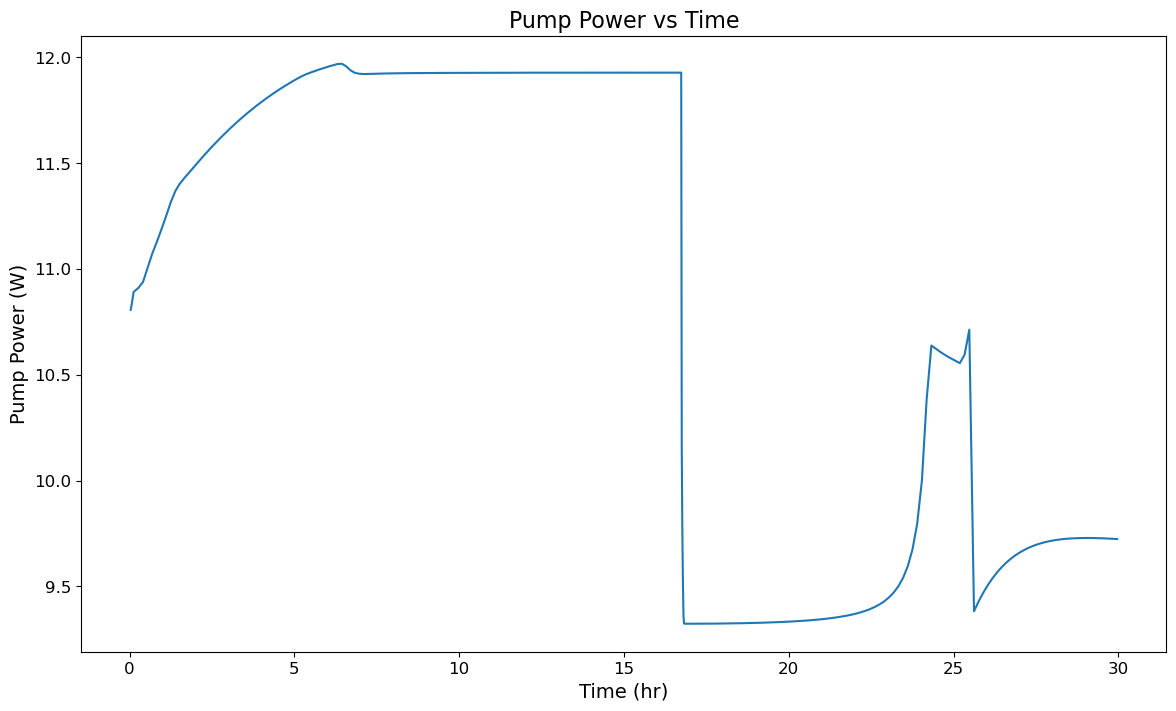

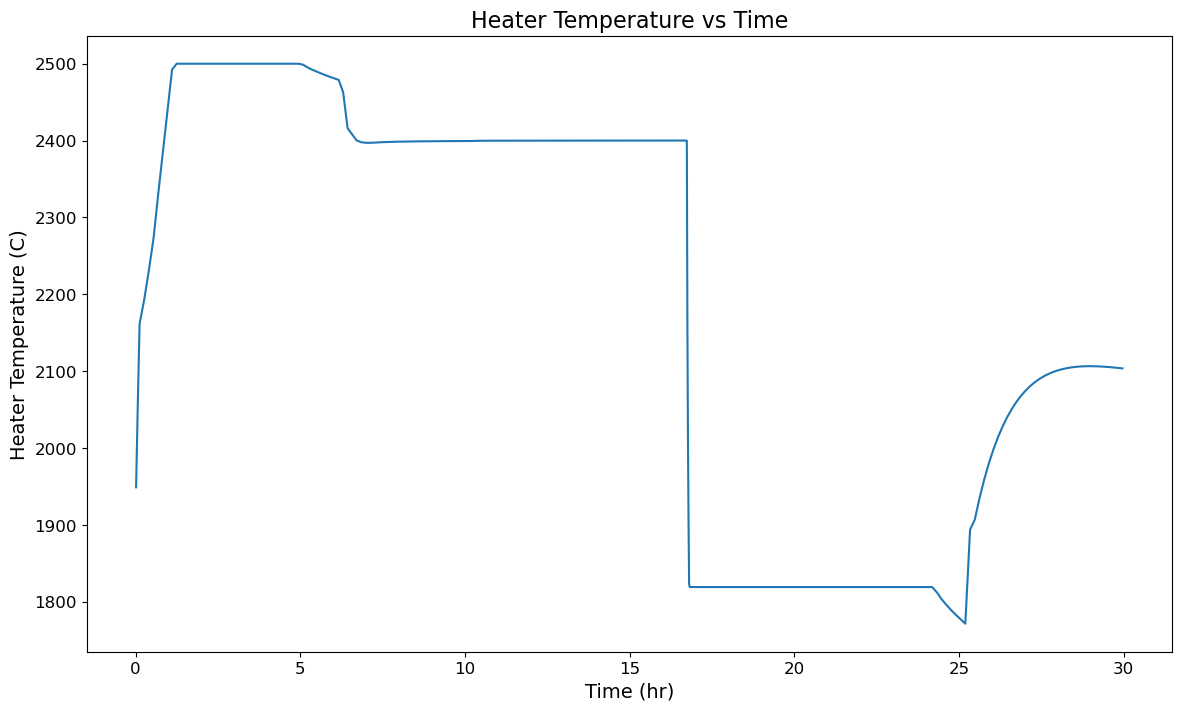

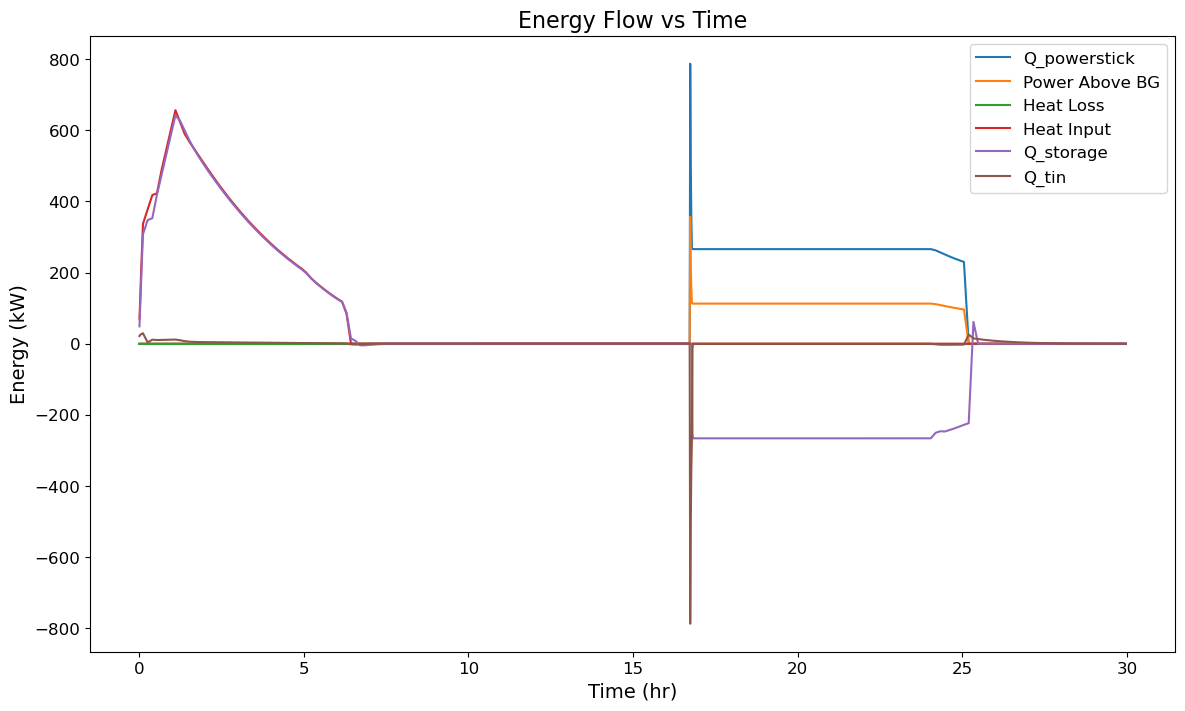

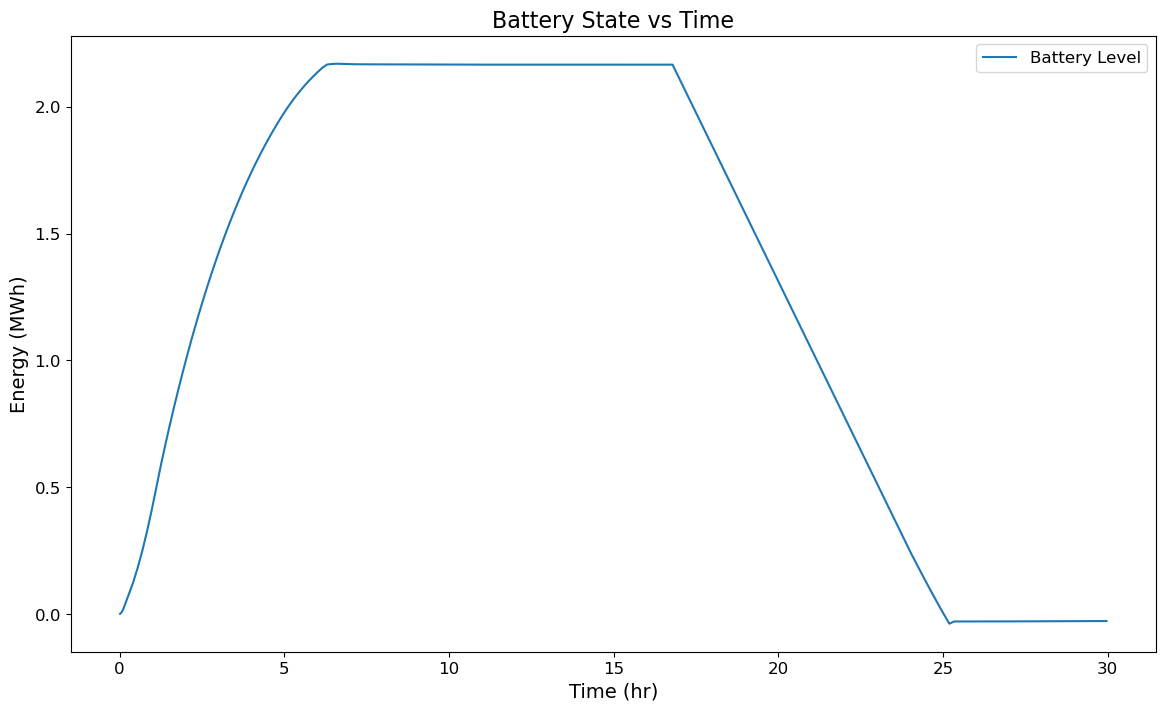

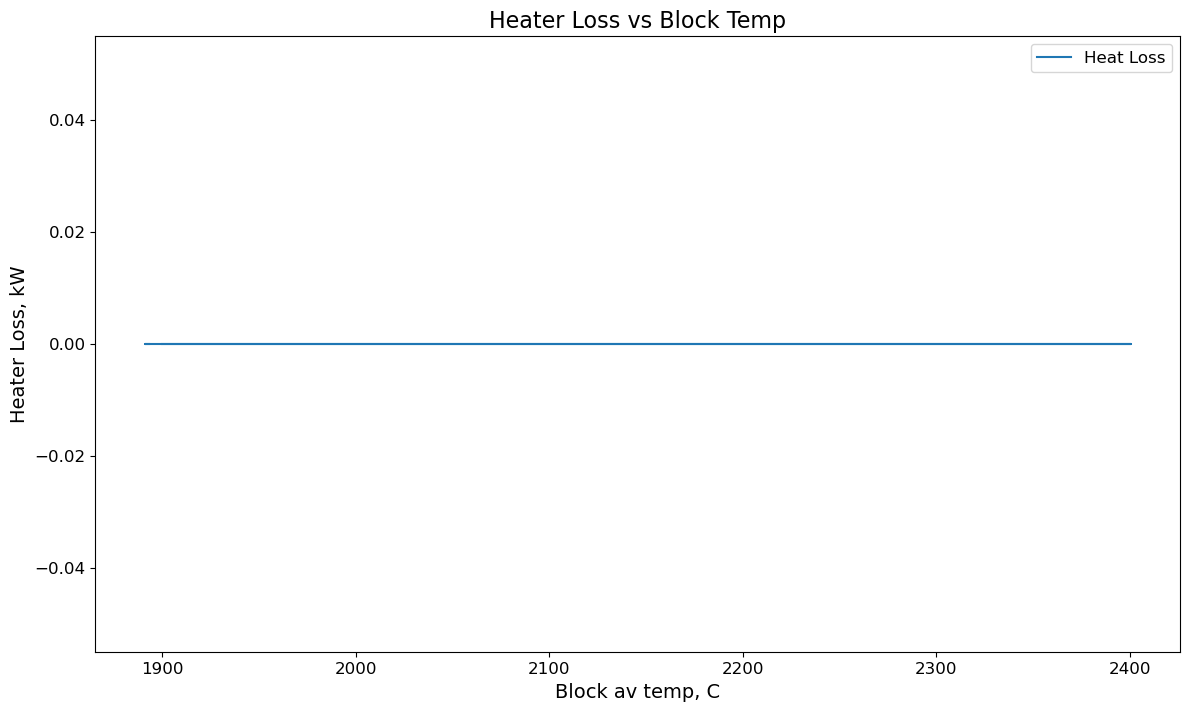

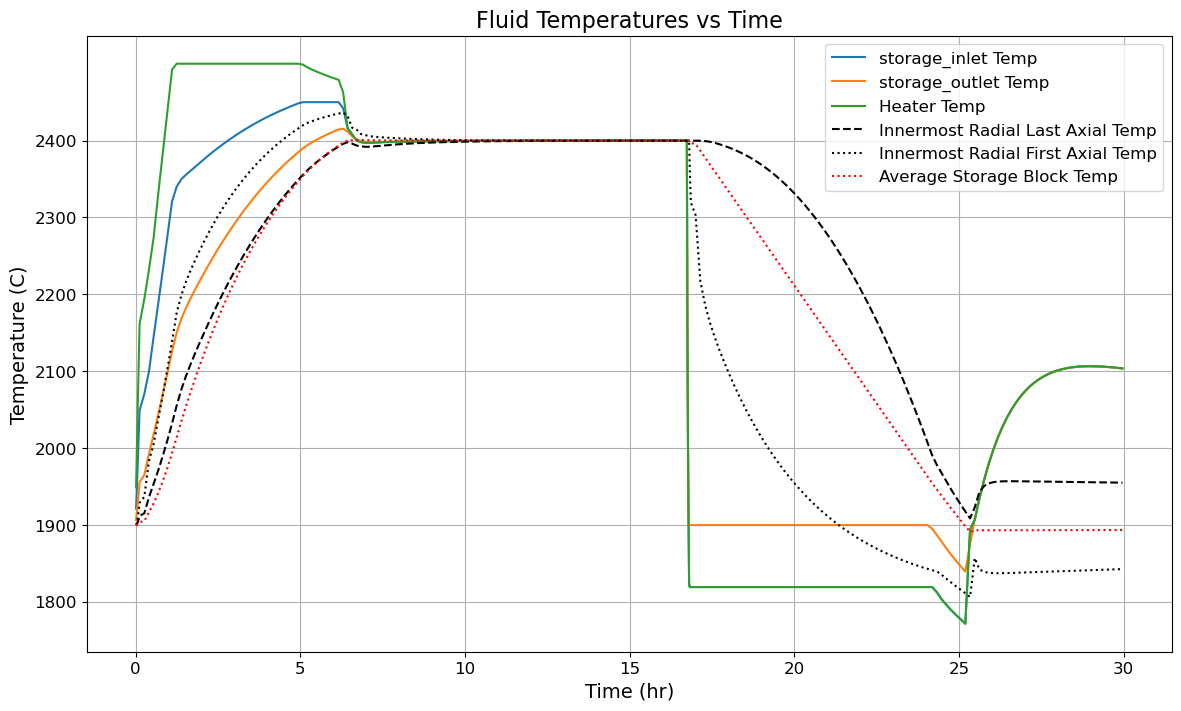

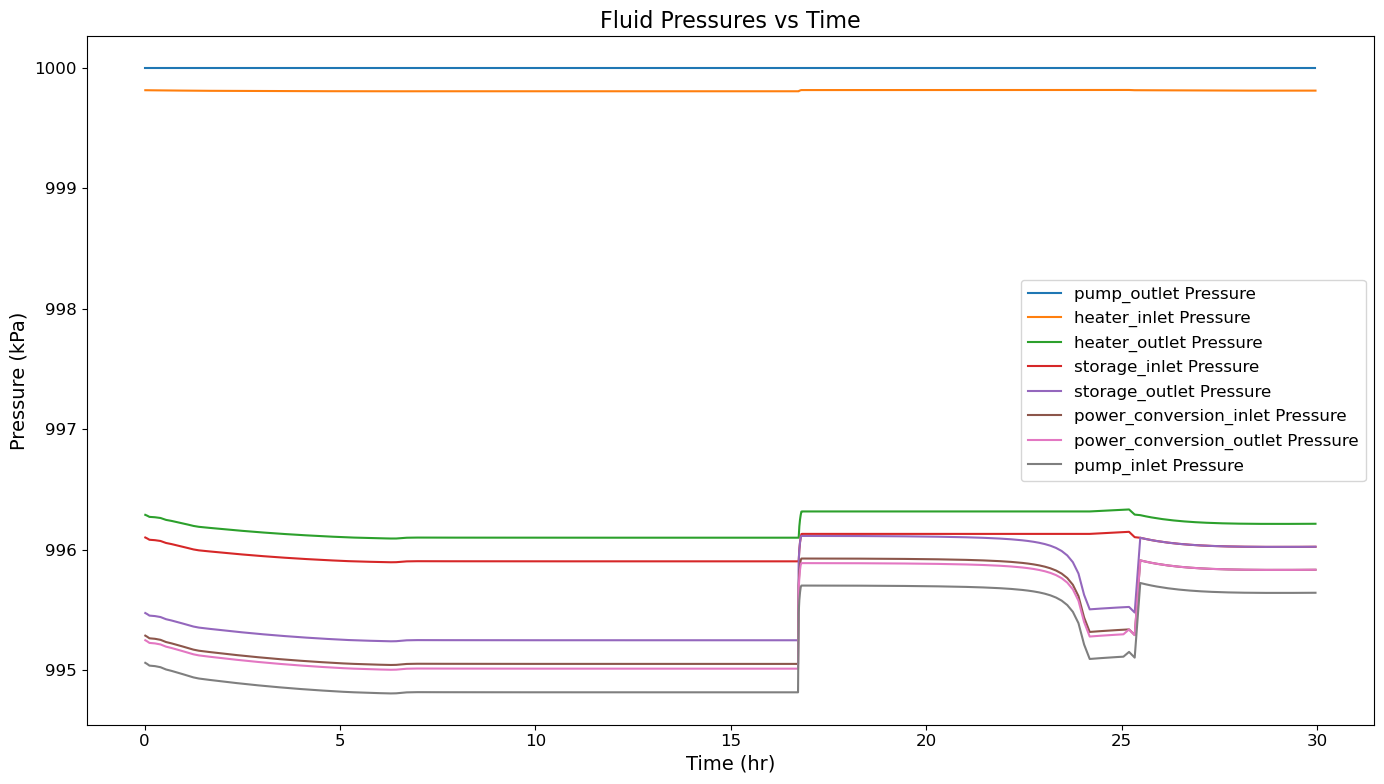

In [212]:
import imageio.v2 as imageio
import os
import shutil
def plot_temperature_distribution(temp_dist, time, length, r_inner, r_outer, vmin, vmax, filename):
    """
    Plot the temperature distribution as a 2D colormap.
    
    Parameters:
    temp_dist (2D array): Temperature distribution in the storage block (K).
    length (float): Length of the storage block (m).
    r_inner (float): Internal radius of the storage block (m).
    r_outer (float): External radius of the storage block (m).
    vmin (float): Minimum temperature value for the colormap.
    vmax (float): Maximum temperature value for the colormap.
    """
    temp_dist = np.transpose(temp_dist)
    num_rad_segments, num_ax_segments = temp_dist.shape
    dr = (r_outer - r_inner) / num_rad_segments
    dz = length / num_ax_segments
    r = np.linspace(r_inner + dr / 2, r_outer - dr / 2, num_rad_segments)
    z = np.linspace(dz / 2, length - dz / 2, num_ax_segments)
    R, Z = np.meshgrid(r, z, indexing='ij')
    cbarticks = np.arange(np.floor(vmin/100) * 100, np.ceil(vmax / 100) * 100, (np.ceil(vmax / 100) - np.floor(vmin/100)) * 5)
    plt.figure(figsize=(10, 6))
    plt.contourf(Z, R, temp_dist, cbarticks, cmap='hot', vmin=vmin, vmax=vmax)
    plt.colorbar(label='Temperature (C)', ticks = cbarticks)
    plt.xlabel('Axial Position (m)')
    plt.ylabel('Radial Position (m)')
    plt.title(f'Temperature Distribution in the Storage Block at t={time: .2f} hrs')
    plt.savefig(filename)
    plt.close()
    #plt.show()

def create_new_folder(base_folder='plots', label='plot'):
    """Creates a new folder with an incremented number in the base folder."""
    if not os.path.exists(base_folder):
        os.makedirs(base_folder)
    
    # Get the list of existing folders
    existing_folders = [f for f in os.listdir(base_folder) if os.path.isdir(os.path.join(base_folder, f))]
    # Extract numbers from folder names
    existing_numbers = [int(folder.split('_')[-1]) for folder in existing_folders if folder.startswith(f'{label}_')]
    # Determine the new folder number
    new_number = max(existing_numbers, default=0) + 1
    
    # Create the new folder
    new_folder = os.path.join(base_folder, f'{label}_{new_number}')
    os.makedirs(new_folder)
    
    return new_folder

def copy_yaml_file(folder, yaml_file='simulation_input_template.yaml'):
    """Copies the YAML file to the specified folder."""
    if os.path.exists(yaml_file):
        shutil.copy(yaml_file, folder)
    else:
        print(f"YAML file '{yaml_file}' not found.")

# Process the results and generate plots
time = np.array(results["time"]) / 3600  # Convert time to hours
# Extract data for plotting
pump_power = results["pump_power"]
heater_temp = np.array(results["heater_temp"]) - 273.15
heater_power = np.array(results["heater_power"]) / 1000 #convert to kW
power_generated = np.array(results["power_generated"]) / 1000  # Convert to kW
waste_heat = np.array(results["waste_heat"]) / 1000  # Convert to kW
pipe_heat_loss = np.array(results["Pipe_heat_loss"]) / 1000  # Convert to kW
Q_storage = np.array(results["Q_storage"]) / 1000  # Convert to kW
Q_tin = np.array(results["Q_tin"]) / 1000  # Convert to kW
batt_level = np.array(results["batt_level"])
flowrate = np.array(results["flowrate"])

# Extract the temperature of the innermost radial, last axial step storage block cell
num_iterations = len(results["time"])
innermost_radial_last_axial_temp = np.array([results["storage_temp_dist"][iteration][-1, 0] for iteration in range(num_iterations)]) - 273.15
innermost_radial_first_axial_temp = np.array([results["storage_temp_dist"][iteration][0, 0] for iteration in range(num_iterations)]) - 273.15
# Calculate the average storage block temperature
#average_storage_temp = np.array([np.mean(results["storage_temp_dist"][iteration]) for iteration in range(num_iterations)]) - 273.15
average_storage_temp = np.array(results["T_av_storage"]) - 273.15
# Calculate the integral of Q_storage with non-static iteration duration
iteration_durations = np.diff(np.array(results["time"]))
Q_storage_integral = np.cumsum(Q_storage[1:] * iteration_durations)
Q_block_full = V_storage * DT_batt * storage_cp(2448) * storage_rho(2448) / 1000
print(Q_storage_integral[-1]/3.6e6, max(batt_level), Q_block_full/3.6e6)
Electricity_integral = np.cumsum(power_generated[:-1] * iteration_durations)

# Extract fluid temperatures and pressures
fluid_labels_pressure = ["pump_outlet", "heater_inlet", "heater_outlet", "storage_inlet", "storage_outlet", "power_conversion_inlet", "power_conversion_outlet", "pump_inlet"]
fluid_labels_temp = ["storage_inlet","storage_outlet"]
fluid_temps = {label: [] for label in fluid_labels_temp}
fluid_pressures = {label: [] for label in fluid_labels_pressure}
# Determine the global min and max temperatures for consistent colormap scaling
vmin = np.min(results["storage_temp_dist"]) - 273.15
vmax = np.max(results["storage_temp_dist"]) - 273.15

block_params = {k: v for k, v in input_data["storage"]["Block"].items() if k != "initial_temp"}
V_storage = input_data["storage"]["Volume"]
N_blocks = input_data["storage"]["N_pipes"]
inner_radius = input_data["storage"]["Block"]["inner_radius"]
length = input_data["storage"]["Block"]["length"]
outer_radius = np.sqrt(V_storage / (N_blocks * length * np.pi) + inner_radius**2)
block_params["outer_radius"] = outer_radius
filenames = []
n_frames = 72
# Create a new folder to save the plots
new_folder = create_new_folder()
# Copy the YAML file to the new folder
copy_yaml_file(new_folder)
# Iterate over the actual number of simulation iterations
for iteration in range(num_iterations):
    for label in fluid_labels_temp:
        fluid_temps[label].append(results["fluid_conditions"][label][iteration].temperature)
    for label in fluid_labels_pressure:
        fluid_pressures[label].append(results["fluid_conditions"][label][iteration].pressure / 1000)

    # Plot storage temperature distribution over n frames
    current_time = time[iteration]
    if iteration == 0 or np.ceil(time[iteration]) > np.ceil(time[iteration - 1]):#  % np.round(time_steps / n_frames) == 0:
        filename = os.path.join(new_folder, f'storage_temp_dist_{np.round(current_time, 0)}.png')
        plot_temperature_distribution(
            results["storage_temp_dist"][iteration] - 273.15, np.round(current_time, 0),
            block_params["length"], 
            block_params["inner_radius"], 
            block_params["outer_radius"], vmin, vmax, filename
        )
        filenames.append(filename)

# Create GIF from the storage temperature distribution images
gif_path = os.path.join(new_folder, 'storage_temp_dist.gif')
with imageio.get_writer(gif_path, mode='I', duration=10) as writer:
    for filename in filenames:
        image = imageio.imread(filename)
        writer.append_data(image)

# Convert lists to numpy arrays for plotting
for label in fluid_labels_temp:
    fluid_temps[label] = np.array(fluid_temps[label]) - 273.15
for label in fluid_labels_pressure:
    fluid_pressures[label] = np.array(fluid_pressures[label])

# Create plots
#set default plot format
plt.rc('font', size=12)          # Default text size
plt.rc('axes', titlesize=16)     # Axes title size
plt.rc('axes', labelsize=14)     # Axes labels size
plt.rc('xtick', labelsize=12)    # X-tick labels size
plt.rc('ytick', labelsize=12)    # Y-tick labels size
plt.rc('legend', fontsize=12)    # Legend font size

# Plot pump power
plt.figure(figsize=(14, 8))
plt.plot(time[1:], pump_power[1:])
plt.xlabel('Time (hr)')
plt.ylabel('Pump Power (W)')
plt.title('Pump Power vs Time')
plot_path = os.path.join(new_folder, 'pump_power.png')
plt.savefig(plot_path)

# Plot heater temperature
plt.figure(figsize=(14, 8))
plt.plot(time, heater_temp)
plt.xlabel('Time (hr)')
plt.ylabel('Heater Temperature (C)')
plt.title('Heater Temperature vs Time')
plt.savefig(os.path.join(new_folder, 'heater_temp.png'))

# Plot waste heat, electricity, pipe heat loss, heat input, and Q_storage
plt.figure(figsize=(14, 8))
plt.plot(time, waste_heat + power_generated, label='Q_powerstick')
plt.plot(time, power_generated, label='Power Above BG')
plt.plot(time, pipe_heat_loss, label='Heat Loss')
plt.plot(time, heater_power, label='Heat Input')
plt.plot(time, Q_storage, label='Q_storage')
plt.plot(time, Q_tin, label='Q_tin')
plt.xlabel('Time (hr)')
plt.ylabel('Energy (kW)')
plt.title('Energy Flow vs Time')
plt.legend()
plt.savefig(os.path.join(new_folder, 'energy_flow.png'))

# Slide 12: Integral of Q Storage Plot
plt.figure(figsize=(14, 8))
#plt.plot(time[:-1], Q_storage_integral / 3.6e6, label='Stored Energy')
plt.plot(time[:], batt_level, label='Battery Level')
plt.xlabel('Time (hr)')
plt.ylabel('Energy (MWh)')
plt.title('Battery State vs Time')
plt.legend()
plt.savefig(os.path.join(new_folder, 'storage_energy.png'))

# Slide 12: Integral of Q Storage Plot
plt.figure(figsize=(14, 8))
plt.plot(average_storage_temp, pipe_heat_loss, label='Heat Loss')
#plt.plot(fluid_temps["heater_inlet"], heater_power, label='Power')
plt.xlabel('Block av temp, C')
plt.ylabel('Heater Loss, kW')
plt.title('Heater Loss vs Block Temp')
plt.legend()
plt.savefig(os.path.join(new_folder, 'flowrate.png'))

# Plot fluid temperatures
plt.figure(figsize=(14, 8))
for label in fluid_labels_temp:
    plt.plot(time, fluid_temps[label], label=f'{label} Temp')
if simple_heater_bool == False:
    plt.plot(time, heater_temp, label='Heater Temp')
plt.plot(time, innermost_radial_last_axial_temp, label='Innermost Radial Last Axial Temp', linestyle='--', color='black')
plt.plot(time, innermost_radial_first_axial_temp, label='Innermost Radial First Axial Temp', linestyle=':', color='black')
plt.plot(time, average_storage_temp, label='Average Storage Block Temp', linestyle=':', color='red')
plt.xlabel('Time (hr)')
plt.ylabel('Temperature (C)')
plt.yticks(np.arange(np.floor(vmin / 100) * 100, np.ceil(vmax / 100) * 100, 100))
plt.title('Fluid Temperatures vs Time')
plt.legend(loc='best')
plt.grid(True)
plt.savefig(os.path.join(new_folder, 'Temperatures.png'))

# Plot fluid pressures
plt.figure(figsize=(14, 8))
for label in fluid_labels_pressure:
    plt.plot(time, fluid_pressures[label], label=f'{label} Pressure')
plt.xlabel('Time (hr)')
plt.ylabel('Pressure (kPa)')
plt.title('Fluid Pressures vs Time')
plt.legend()
plt.tight_layout()
#plt.show()
plt.savefig(os.path.join(new_folder, 'Pressures.png'))

# Calculate max temperature rise rate for storage block
max_storage_rise_rate = -np.inf
max_storage_rise_location = None
max_storage_rise_time = None

for i in range(num_iterations-1):
    temp_prev = results["storage_temp_dist"][i]
    temp_next = results["storage_temp_dist"][i+1]
    dt = results["time"][i+1] - results["time"][i]
    # Calculate rise rate for this step (K/s)
    rise_rate = (temp_next - temp_prev) / dt
    max_rise = np.max(rise_rate)
    if max_rise > max_storage_rise_rate:
        max_storage_rise_rate = max_rise
        # Find location (radial, axial) of max rise
        loc = np.unravel_index(np.argmax(rise_rate), rise_rate.shape)
        max_storage_rise_location = loc
        max_storage_rise_time = 0.5*(results["time"][i] + results["time"][i+1])

print(f"Max storage block temperature rise rate: {max_storage_rise_rate*60:.4f} K/min")
print(f"  at location (radial, axial): {max_storage_rise_location}")
print(f"  at time: {max_storage_rise_time/3600:.2f} hr")

# Calculate max temperature rise rate for each fluid temperature location
max_fluid_rise_rates = {}
max_fluid_rise_times = {}
for label in fluid_labels_temp:
    T = np.array([results["fluid_conditions"][label][i].temperature for i in range(num_iterations)])
    rise_rate = np.diff(T) / np.diff(results["time"])
    max_idx = np.argmax(rise_rate)
    max_fluid_rise_rates[label] = rise_rate[max_idx]
    max_fluid_rise_times[label] = 0.5*(results["time"][max_idx] + results["time"][max_idx+1])
    print(f"Max {label} temperature rise rate: {rise_rate[max_idx]*60:.4f} K/min at t = {max_fluid_rise_times[label]/3600:.2f} hr")

In [48]:
# Run matrix of cases
# Load the input file
with open("simulation_input_template.yaml", "r") as file:
    input_data = yaml.safe_load(file)

# Helper function to generate time series from range definitions
def generate_time_series(range_definitions, time_steps):
    series = np.zeros(time_steps)
    for item in range_definitions:
        start, end = item['range']
        series[start:end+1] = item['value']
    return series

# Helper function to generate time series for emissivity table
def generate_emissivity_table_series(range_definitions, time_steps):
    series = [[] for _ in range(time_steps)]
    for item in range_definitions:
        start, end = item['range']
        for i in range(start, end+1):
            series[i] = [(tuple(pair[0]), float(pair[1]), float(pair[2]), float(pair[3])) for pair in item['value']]  # Ensure each entry is a list of tuples
    return series

# Helper function to generate uniform 2D temperature distribution
def generate_2d_temp_distribution(initial_temp, num_ax_segments, num_rad_segments):
    return np.full((num_ax_segments, num_rad_segments), initial_temp)

def create_new_folder(base_folder, label):
    """Creates a new folder with an incremented number in the base folder."""
    if not os.path.exists(base_folder):
        os.makedirs(base_folder)
    
    # Get the list of existing folders
    existing_folders = [f for f in os.listdir(base_folder) if os.path.isdir(os.path.join(base_folder, f))]
    
    # Extract numbers from folder names
    existing_numbers = [int(folder.split('_')[-1]) for folder in existing_folders if folder.startswith(f'{label}_')]
    
    # Determine the new folder number
    new_number = max(existing_numbers, default=0) + 1
    
    # Create the new folder
    new_folder = os.path.join(base_folder, f'{label}_{new_number}')
    os.makedirs(new_folder)
    
    return new_folder

def save_input_config(file_path, input_data):
    """
    Save the input configuration to a YAML file.
    
    Parameters:
    file_path (str): Path to the input configuration file.
    input_data (dict): Input configuration data.
    """
    with open(file_path, 'w') as file:
        yaml.dump(input_data, file)

def save_results(file_path, results):
    """
    Save the simulation results to a YAML file.
    
    Parameters:
    file_path (str): Path to the results file.
    results (dict): Simulation results data.
    """
    with open(file_path, 'w') as file:
        yaml.dump(results, file)

# Extract the parameters from the input file
time_steps = input_data["time_steps"]
end_time = input_data["end_time"]
heat_loss_bool = input_data["heat_loss_bool"]
simple_heater_bool = input_data["simple_heater_bool"]
vary_flowrate_bool = input_data["vary_flowrate_bool"]
N_loops_step = input_data["N_loops_step"]
print_outputs_bool = input_data["print_outputs_bool"]

emissivity_tables = generate_emissivity_table_series(input_data["emissivity_tables"], time_steps)
#power_bypass = generate_time_series(input_data["power_conversion_bypass_fractions"], time_steps)

initial_conditions = input_data["initial_fluids"]
N_stations = input_data["N_stations"]
T_sur = input_data["T_sur"]
# Create the components
pump = Pump(pump_efficiency=input_data["pump"]["efficiency"])

#define test cases
#heating_rates = [1]
#bypass_bools = [True, False]
#powerstick_lengths = [1, 1.5, 3]
#num_storage_blocks = [5,7,10]
num_blocks_per_row = [1, 2, 4, 6, 12]
base_block_length = 2.8
tot_num_blocks = 648
#block_in_rads = [0.03, .05, .08, 0.12, 0.18, 0.24, 0.30]
#block_in_rads = [0.03,0.15,0.3]
flow_rate_vals = [700,1400,3500]
#N_heater_pipes = [3, 6, 9]
#gas_dir_emis_vals = [0.05, 0.1, 0.2, 0.4, 0.8]
T_emitter_lims = [2523]
heating_rates = [1]
bypass_bools = [True]
#num_storage_blocks = [8, 16, 32]
#flow_rate_vals = [7.0, 21.0, 35.0]
powerstick_lengths = [3]
#num_storage_blocks = np.logspace(8,80,10)
# Directory to save input configurations
input_dir = "test_matrices"
os.makedirs(input_dir, exist_ok=True)
#results = np.empty((len(heating_rates), len(T_emitter_lims), len(num_storage_blocks), len(bypass_bools), len(flow_rate_vals)), dtype=object)
results = np.empty((len(num_blocks_per_row), len(flow_rate_vals)), dtype=object)
new_folder = create_new_folder(base_folder=input_dir, label='run')
#for i, heating_rate in enumerate(heating_rates):
for i, blocks_per_row in enumerate(num_blocks_per_row):
    for j, flow_rate_val in enumerate(flow_rate_vals):
    #for j, powerstick_length in enumerate(powerstick_lengths):
    #for j, block_in_rad in enumerate(block_in_rads):
        #for k, num_blocks in enumerate(num_storage_blocks):
        #    for m, bypass_bool in enumerate(bypass_bools):
        #        for n, flow_rate_val in enumerate(flow_rate_vals):
        #flow_rate_val = flow_rates[0]
        input_data["storage"]["N_pipes"] = int(tot_num_blocks / blocks_per_row)
        heating_rate = heating_rates[0]
        #num_blocks = num_storage_blocks[0]
        bypass_bool = bypass_bools[0]
        powerstick_length = powerstick_lengths[0]
        input_data["power_conversion"]["max_inlet_temp"] = T_emitter_lims[0]
        #for entry in input_data["emissivity_tables"]:
        #    for value in entry['value']:
        #        value[2] = gas_dir_emis_val
        #emissivity_tables = generate_emissivity_table_series(input_data["emissivity_tables"], time_steps)
        #reset initial fluids
                    #N_loops_step = int(flow_rate_val) #rough way to scale speed up to not induce instability
                    #N_loops_step = min(int(flow_rate_val), input_data["N_loops_step"])
        N_loops_step = input_data["N_loops_step"]
        initial_fluids = [Fluid(temperature=float(initial_conditions["temperature"]),
            pressure=float(initial_conditions["pressure"]),
            flow_rate=1) for _ in range(N_stations)]
        #update varied parameters
        input_data["heat_inputs"] = heat_inputs = [{"range": [0, input_data["time_steps"] - 1], "value": heating_rate}]
        #half_time_steps = time_steps // 2
        #input_data["heat_inputs"] = [{"range": [0, half_time_steps - 1], "value": heating_rate},
        #                             {"range": [half_time_steps, time_steps - 1], "value": 0}]
        input_data["flow_rates"] = flow_rates = [{"range": [0, input_data["time_steps"] - 1], "value": flow_rate_val}]
        input_data["power_conversion"]["length"] = powerstick_length
        #input_data["storage"]["N_pipes"] = num_blocks
        #input_data["storage"]["Block"]["inner_radius"] = block_in_rad
        input_data["bypass_bool"] = bypass_bool
        #generate input time series
        heat_inputs = generate_time_series(input_data["heat_inputs"], time_steps)
        flow_rates = generate_time_series(input_data["flow_rates"], time_steps)
        
        heater = HeatingModule(heat_input=input_data["heater"]["heat_input"], N_pipes=input_data["heater"]["N_pipes"],
                               Pipe=Pipe(**input_data["heater"]["Pipe"]), simple_heat=simple_heater_bool)
        pipe_template = Pipe(**input_data["storage"]["Pipe"])
        
        # Generate initial temperature distribution as a 2D array
        num_ax_segments = input_data["storage"]["num_ax_segments"]
        num_rad_segments = input_data["storage"]["num_rad_segments"]
        initial_temp = input_data["storage"]["Block"]["initial_temp"]
        initial_temp_distribution = generate_2d_temp_distribution(initial_temp, num_ax_segments, num_rad_segments)
        
        block_params = {k: v for k, v in input_data["storage"]["Block"].items() if k != "initial_temp"}
        
        storage_bypass_range = input_data["storage"]["Bypass"]["range"]
        V_storage = input_data["storage"]["Volume"]
        #N_blocks = input_data["storage"]["N_pipes"]
        length = input_data["storage"]["Block"]["length"]
        block_params["length"] = base_block_length * blocks_per_row
        block_in_rad = block_params["inner_radius"]
        outer_radius = np.sqrt(V_storage / (tot_num_blocks / blocks_per_row * length * np.pi) + block_in_rad**2)
        block_params["outer_radius"] = outer_radius
        storage = StorageModule(Block=GraphiteBlock(initial_temp_distribution, **block_params),  
                                N_pipes=input_data["storage"]["N_pipes"], 
                                Pipe=pipe_template, 
                                num_ax_segments=input_data["storage"]["num_ax_segments"], 
                                num_rad_segments=input_data["storage"]["num_rad_segments"],
                                bypass_range=storage_bypass_range)
        power_conversion = PowerConversionBlock(
            axial_steps=int(input_data["power_conversion"]["axial_steps"]),
            N_cells=int(input_data["power_conversion"]["N_cells"]),
            height_pipe=float(input_data["power_conversion"]["height_pipe"]),
            width_emitter=float(input_data["power_conversion"]["width_emitter"]),
            length=float(input_data["power_conversion"]["length"]),
            roughness_pipe=float(input_data["power_conversion"]["roughness_pipe"]),
            width_powerstick=float(input_data["power_conversion"]["width_powerstick"]),
            wall_thickness=float(input_data["power_conversion"]["wall_thickness"]),
            cooling_temp=float(input_data["power_conversion"]["cooling_temp"]),
            panel_efficiency=float(input_data["power_conversion"]["panel_efficiency"]),
            T_tin_max_PCB=input_data["power_conversion"]["max_inlet_temp"],
            f_bare=input_data["power_conversion"]["f_bare"],
            f_active=input_data["power_conversion"]["f_active"],
            emissivity_table=emissivity_tables[0]
            
        )
        pipes = [Pipe(**pipe) for pipe in input_data["pipes"]]
        
        # Create the system simulation
        simulation = SystemSimulation(pump, heater, storage, power_conversion, pipes, heat_loss_bool, bypass_bool, vary_flowrate_bool, print_outputs_bool, N_loops_step)
        # Run the simulation
        #print("Case: Heat rate:", heating_rate, "stick length:", powerstick_length, "num_blocks", num_blocks, "Bypass: ", bypass_bool, "flowrate: ", flow_rate_val)
        print("Case: Heat rate:", heating_rate, "num blocks per row:", blocks_per_row, "Max flowrate: ", flow_rate_val)
        result = simulation.run_simulation(initial_fluids, end_time, heat_inputs, flow_rates, emissivity_tables, T_sur)
        results[i, j] = result
        # Save the input configuration
        #file_name = f"input_hr{heating_rate}_pl{powerstick_length}_sb{num_blocks}.yaml"
        file_name = f"input_hr{heating_rate}_sbr{blocks_per_row}_fr{flow_rate_val}.yaml"
        file_path = os.path.join(new_folder, file_name)
        save_input_config(file_path, input_data)
        # Save the results
        results_file_name = f"results_hr{heating_rate}_sbr{blocks_per_row}_fr{flow_rate_val}.yaml"
        results_file_path = os.path.join(new_folder, results_file_name)
        save_results(results_file_path, result)
            


KeyError: 'temperature'

18000
Case: num_blocks 7
100000.0 550000.0 1000000.0 1.001441111688258 0.98
final batt level:  1.001441111688258
100000.0 325000.0 550000.0 0.7800445335296865 0.98
final batt level:  0.7800445335296865
344995.5466470313 447497.77332351566 550000.0 0.9607069662464881 0.98
final batt level:  0.9607069662464881
449427.07669886685 499713.53834943345 550000.0 0.9865470137085217 0.98
final batt level:  0.9865470137085217
449427.07669886685 474570.3075241501 499713.53834943345 0.9756693886151137 0.98
final batt level:  0.9756693886151137
475570.3075241501 487641.9229367918 499713.53834943345 0.9816335209250338 0.98
final batt level:  0.9816335209250338
475570.3075241501 481606.11523047095 487641.9229367918 0.9789649535301176 0.98
final batt level:  0.9789649535301176
482606.11523047095 485124.01908363134 487641.9229367918 0.9805496004427255 0.98
final batt level:  0.9805496004427255
482606.11523047095 483865.0671570512 485124.01908363134 0.9799828053601659 0.98
final batt level:  0.9799828053

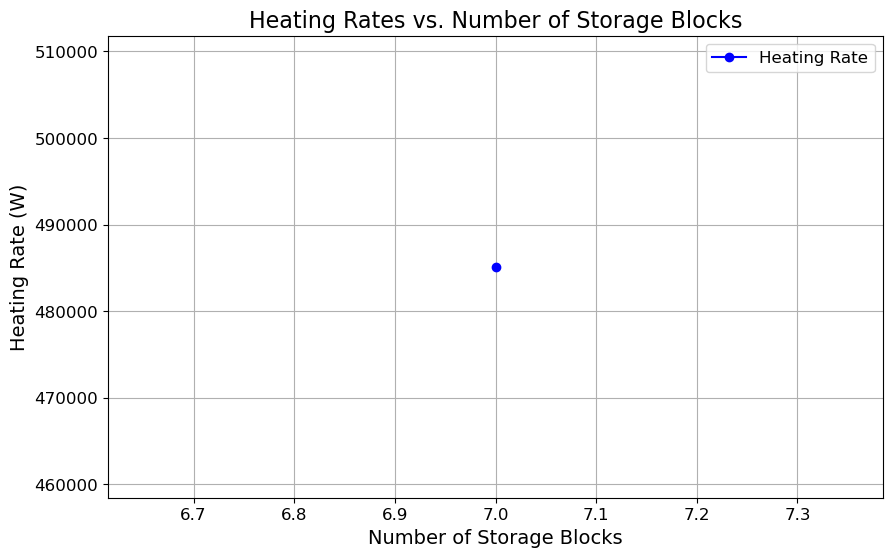

In [194]:
# Case optimization
# Load the input file
with open("simulation_input_template.yaml", "r") as file:
    input_data = yaml.safe_load(file)

# Helper function to generate time series from range definitions
def generate_time_series(range_definitions, time_steps):
    series = np.zeros(time_steps)
    for item in range_definitions:
        start, end = item['range']
        series[start:end+1] = item['value']
    return series

# Helper function to generate time series for emissivity table
def generate_emissivity_table_series(range_definitions, time_steps):
    series = [[] for _ in range(time_steps)]
    for item in range_definitions:
        start, end = item['range']
        for i in range(start, end+1):
            series[i] = [(tuple(pair[0]), float(pair[1]), float(pair[2]), float(pair[3])) for pair in item['value']]  # Ensure each entry is a list of tuples
    return series

# Helper function to generate uniform 2D temperature distribution
def generate_2d_temp_distribution(initial_temp, num_ax_segments, num_rad_segments):
    return np.full((num_ax_segments, num_rad_segments), initial_temp)

def create_new_folder(base_folder, label):
    """Creates a new folder with an incremented number in the base folder."""
    if not os.path.exists(base_folder):
        os.makedirs(base_folder)
    
    # Get the list of existing folders
    existing_folders = [f for f in os.listdir(base_folder) if os.path.isdir(os.path.join(base_folder, f))]
    
    # Extract numbers from folder names
    existing_numbers = [int(folder.split('_')[-1]) for folder in existing_folders if folder.startswith(f'{label}_')]
    
    # Determine the new folder number
    new_number = max(existing_numbers, default=0) + 1
    
    # Create the new folder
    new_folder = os.path.join(base_folder, f'{label}_{new_number}')
    os.makedirs(new_folder)
    
    return new_folder

def save_input_config(file_path, input_data):
    """
    Save the input configuration to a YAML file.
    
    Parameters:
    file_path (str): Path to the input configuration file.
    input_data (dict): Input configuration data.
    """
    with open(file_path, 'w') as file:
        yaml.dump(input_data, file)

def save_results(file_path, results):
    """
    Save the simulation results to a YAML file.
    
    Parameters:
    file_path (str): Path to the results file.
    results (dict): Simulation results data.
    """
    with open(file_path, 'w') as file:
        yaml.dump(results, file)
        
# Function to check if the system reaches full charge
def is_fully_charged(results, target_state):
    """
    Check if the system reaches the full charge condition.
    Modify this function to reflect your definition of 'fully charged' (e.g., temperature, energy).
    """
    final_batt_level = np.array(results["batt_level"])[-1] / (V_storage * DT_batt * storage_cp(2448) * storage_rho(2448) / 3.6e9)
    print("final batt level: ", final_batt_level)
    # Example: Check if the final state variable (e.g., energy or temperature) meets or exceeds the target
    return final_batt_level >= target_state

# Binary search to find the minimum heating rate
def find_min_heating_rate(simulation, initial_fluids, end_time, flow_rates, emissivity_tables, T_sur, time_steps, input_data, target_state):
    low = 1e5  # Minimum heating rate (arbitrary starting point)
    high = 1e6  # Maximum heating rate (arbitrary high value)
    tolerance = 1e3  # Stop when the difference between high and low is less than this value
    best_heating_rate = None  # To store the lowest heating rate that meets the target
    while high - low > tolerance:
        mid = (low + high) / 2
        # Reset fluid temperatures and pressures for this test
        initial_fluids = [Fluid(temperature=float(initial_conditions["temperature"]),
        pressure=float(initial_conditions["pressure"]),
        flow_rate=1) for _ in range(N_stations)]

        # Reset storage block temperatures for this test
        num_ax_segments = input_data["storage"]["num_ax_segments"]
        num_rad_segments = input_data["storage"]["num_rad_segments"]
        initial_temp = input_data["storage"]["Block"]["initial_temp"]
        initial_temp_distribution = generate_2d_temp_distribution(initial_temp, num_ax_segments, num_rad_segments)
        
        block_params = {k: v for k, v in input_data["storage"]["Block"].items() if k != "initial_temp"}
        
        storage_bypass_range = input_data["storage"]["Bypass"]["range"]
        V_storage = input_data["storage"]["Volume"]
        #N_blocks = input_data["storage"]["N_pipes"]
        inner_radius = input_data["storage"]["Block"]["inner_radius"]
        length = input_data["storage"]["Block"]["length"]
        outer_radius = np.sqrt(V_storage / (num_blocks * length * np.pi) + inner_radius**2)
        block_params["outer_radius"] = outer_radius
        storage = StorageModule(Block=GraphiteBlock(initial_temp_distribution, **block_params),  
                                N_pipes=input_data["storage"]["N_pipes"], 
                                Pipe=pipe_template, 
                                num_ax_segments=input_data["storage"]["num_ax_segments"], 
                                num_rad_segments=input_data["storage"]["num_rad_segments"],
                                bypass_range=storage_bypass_range)

        # Update the heating rate in the input data
        input_data["heat_inputs"] = [{"range": [0, time_steps - 1], "value": mid}]
        heat_inputs = generate_time_series(input_data["heat_inputs"], time_steps)
        
        #print("heat input: ",mid, "fluid temp: ",initial_fluids[0].temperature, "block temp: ",initial_temp)
        # Run the simulation
        simulation = SystemSimulation(pump, heater, storage, power_conversion, pipes, heat_loss_bool, bypass_bool, vary_flowrate_bool, print_outputs_bool, N_loops_step)
        results = simulation.run_simulation(initial_fluids, end_time, heat_inputs, flow_rates, emissivity_tables, T_sur)
        final_batt_level = np.array(results["batt_level"])[-1] / (V_storage * 500 * storage_cp(2448) * storage_rho(2448) / 3.6e9)
        print(low,mid,high,final_batt_level,target_state)
        # Check if the system is fully charged
        if is_fully_charged(results, target_state):
            # If fully charged, continue with bisection
            best_heating_rate = mid
            high = mid
        else:
            # If not fully charged, switch to adaptive search
            # Calculate the error as the difference between the target and the actual value
            #final_batt_level = np.array(results["batt_level"])[-1] / (V_storage * 500 * storage_cp(2448) * storage_rho(2448) / 3.6e9)
            error = target_state - final_batt_level

            # Dynamically adjust the step size based on the error
            step_size = max(tolerance, abs(error) * 1e5)  # Scale the step size with the error

            # Update the lower bound based on the adaptive step size
            low = min(mid + step_size, high)
    # Handle cases where no valid heating rate is found
    if best_heating_rate is None:
        print(f"Warning: No heating rate found to fully charge the system within the allowable range.")
        return high, results
    # Return the minimum heating rate that results in full charge
    return best_heating_rate or low, results

target_state = 0.98
# Extract the parameters from the input file
time_steps = input_data["time_steps"]
print(time_steps)
end_time = input_data["end_time"]
heat_loss_bool = input_data["heat_loss_bool"]
simple_heater_bool = input_data["simple_heater_bool"]
vary_flowrate_bool = input_data["vary_flowrate_bool"]
bypass_bool = input_data["bypass_bool"]
N_loops_step = input_data["N_loops_step"]
print_outputs_bool = input_data["print_outputs_bool"]

emissivity_tables = generate_emissivity_table_series(input_data["emissivity_tables"], time_steps)

initial_conditions = input_data["initial_fluids"]
N_stations = input_data["N_stations"]
T_sur = input_data["T_sur"]
# Create the components
pump = Pump(pump_efficiency=input_data["pump"]["efficiency"])

#heating_rates = [250000, 500000, 750000]
#num_storage_blocks = [1,2,3,4,5,6,8,10,15,20,30,40]
num_storage_blocks = [7]
# Directory to save input configurations
input_dir = "test_matrices"
os.makedirs(input_dir, exist_ok=True)
results = np.empty(len(num_storage_blocks), dtype=object)
result_rates = np.empty(len(num_storage_blocks))
new_folder = create_new_folder(base_folder=input_dir, label='run')
for i, num_blocks in enumerate(num_storage_blocks):
    N_loops_step = input_data["N_loops_step"]
    initial_fluids = [Fluid(temperature=float(initial_conditions["temperature"]),
        pressure=float(initial_conditions["pressure"]),
        flow_rate=1) for _ in range(N_stations)]
    #update varied parameters
    #input_data["heat_inputs"] = heat_inputs = [{"range": [0, input_data["time_steps"] - 1], "value": heating_rate}]
    input_data["storage"]["N_pipes"] = num_blocks
    #generate input time series
    heat_inputs = generate_time_series(input_data["heat_inputs"], time_steps)
    
    heater = HeatingModule(heat_input=input_data["heater"]["heat_input"], N_pipes=input_data["heater"]["N_pipes"],
                           Pipe=Pipe(**input_data["heater"]["Pipe"]), simple_heat=simple_heater_bool)
    pipe_template = Pipe(**input_data["storage"]["Pipe"])
    
    # Generate initial temperature distribution as a 2D array
    num_ax_segments = input_data["storage"]["num_ax_segments"]
    num_rad_segments = input_data["storage"]["num_rad_segments"]
    initial_temp = input_data["storage"]["Block"]["initial_temp"]
    initial_temp_distribution = generate_2d_temp_distribution(initial_temp, num_ax_segments, num_rad_segments)
    
    block_params = {k: v for k, v in input_data["storage"]["Block"].items() if k != "initial_temp"}
    
    storage_bypass_range = input_data["storage"]["Bypass"]["range"]
    V_storage = input_data["storage"]["Volume"]
    #N_blocks = input_data["storage"]["N_pipes"]
    inner_radius = input_data["storage"]["Block"]["inner_radius"]
    length = input_data["storage"]["Block"]["length"]
    outer_radius = np.sqrt(V_storage / (num_blocks * length * np.pi) + inner_radius**2)
    block_params["outer_radius"] = outer_radius
    storage = StorageModule(Block=GraphiteBlock(initial_temp_distribution, **block_params),  
                            N_pipes=input_data["storage"]["N_pipes"], 
                            Pipe=pipe_template, 
                            num_ax_segments=input_data["storage"]["num_ax_segments"], 
                            num_rad_segments=input_data["storage"]["num_rad_segments"],
                            bypass_range=storage_bypass_range)
    
    power_conversion = PowerConversionBlock(
        axial_steps=int(input_data["power_conversion"]["axial_steps"]),
        N_cells=int(input_data["power_conversion"]["N_cells"]),
        height_pipe=float(input_data["power_conversion"]["height_pipe"]),
        width_emitter=float(input_data["power_conversion"]["width_emitter"]),
        length=float(input_data["power_conversion"]["length"]),
        roughness_pipe=float(input_data["power_conversion"]["roughness_pipe"]),
        width_powerstick=float(input_data["power_conversion"]["width_powerstick"]),
        wall_thickness=float(input_data["power_conversion"]["wall_thickness"]),
        cooling_temp=float(input_data["power_conversion"]["cooling_temp"]),
        panel_efficiency=float(input_data["power_conversion"]["panel_efficiency"]),
        T_tin_max_PCB=input_data["power_conversion"]["max_inlet_temp"],
        f_bare=input_data["power_conversion"]["f_bare"],
        f_active=input_data["power_conversion"]["f_active"],
        emissivity_table=emissivity_tables[0]
        
    )
    pipes = [Pipe(**pipe) for pipe in input_data["pipes"]]
    
    # Create the system simulation
    simulation = SystemSimulation(pump, heater, storage, power_conversion, pipes, heat_loss_bool, bypass_bool, vary_flowrate_bool, N_loops_step)
    # Run the simulation
    print("Case: num_blocks", num_blocks)
    min_heating_rate, result = find_min_heating_rate(simulation, initial_fluids, end_time, flow_rates, emissivity_tables, 
                                                       input_data["T_sur"], time_steps, input_data, target_state)
    print(f"Minimum heating rate for {num_blocks} blocks: {min_heating_rate} W")
    result_rates[i] = min_heating_rate
    results[i] = result
    #results[i] = simulation.run_simulation(initial_fluids, end_time, heat_inputs, flow_rates, emissivity_tables, T_sur)
    # Save the input config
    # Save the input configuration
    file_name = f"input_sb{num_blocks}.yaml"
    file_path = os.path.join(new_folder, file_name)
    save_input_config(file_path, input_data)
    # Save the results
    results_file_name = f"results_sb{num_blocks}.yaml"
    results_file_path = os.path.join(new_folder, results_file_name)
    save_results(results_file_path, results[i])
            
# Plot the results
plt.figure(figsize=(10, 6))
plt.plot(num_storage_blocks, result_rates, marker='o', linestyle='-', color='b', label='Heating Rate')

# Add labels and title
plt.xlabel('Number of Storage Blocks')
plt.ylabel('Heating Rate (W)')
plt.title('Heating Rates vs. Number of Storage Blocks')
plt.grid(True)
plt.legend()

# Show the plot
plt.show()

batt charge time:  0
HR=1, FR=700, SB=1
batt charge time:  0
HR=1, FR=1400, SB=1
batt charge time:  0
HR=1, FR=3500, SB=1
batt charge time:  0
HR=1, FR=700, SB=2
batt charge time:  0
HR=1, FR=1400, SB=2
batt charge time:  0
HR=1, FR=3500, SB=2
batt charge time:  0
HR=1, FR=700, SB=4
batt charge time:  0
HR=1, FR=1400, SB=4
batt charge time:  0
HR=1, FR=3500, SB=4
batt charge time:  0
HR=1, FR=700, SB=6
batt charge time:  0
HR=1, FR=1400, SB=6
batt charge time:  0
HR=1, FR=3500, SB=6
batt charge time:  0
HR=1, FR=700, SB=12
batt charge time:  0
HR=1, FR=1400, SB=12
batt charge time:  0
HR=1, FR=3500, SB=12
[648.0, 324.0, 162.0, 108.0, 54.0]


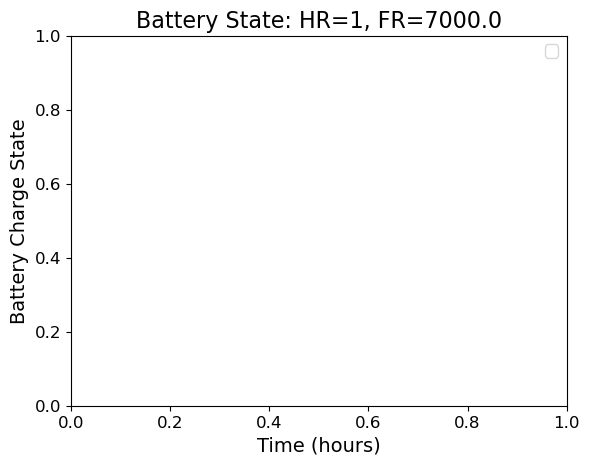

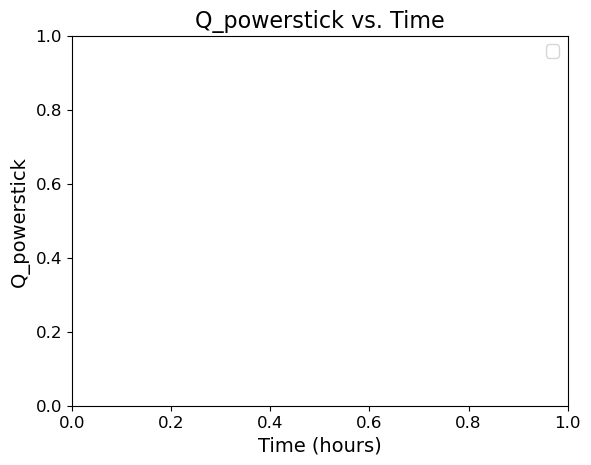

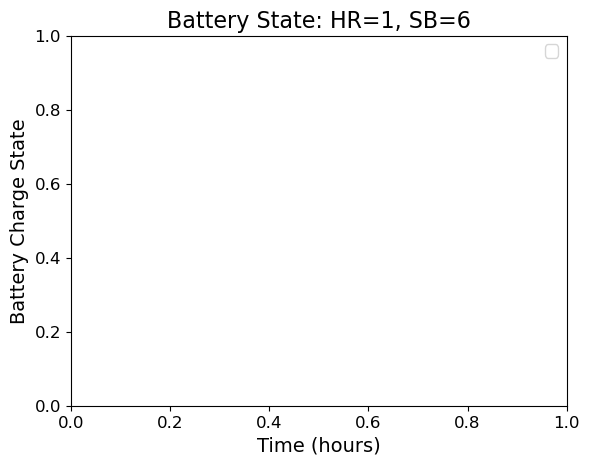

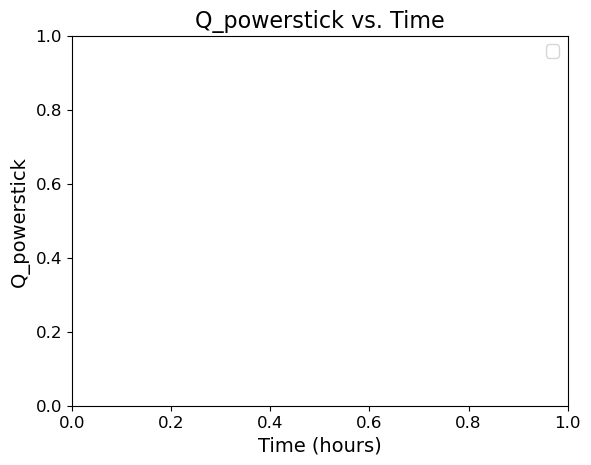

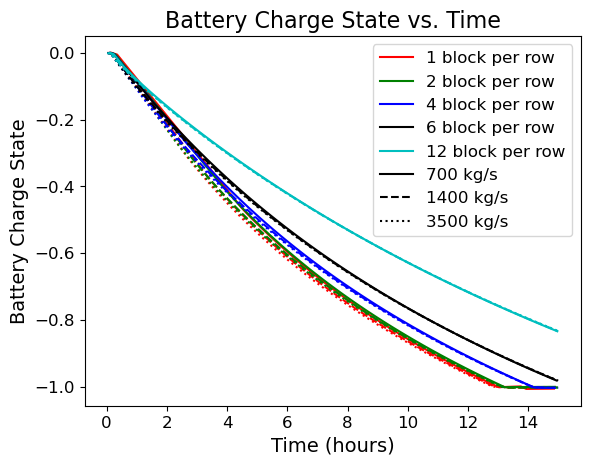

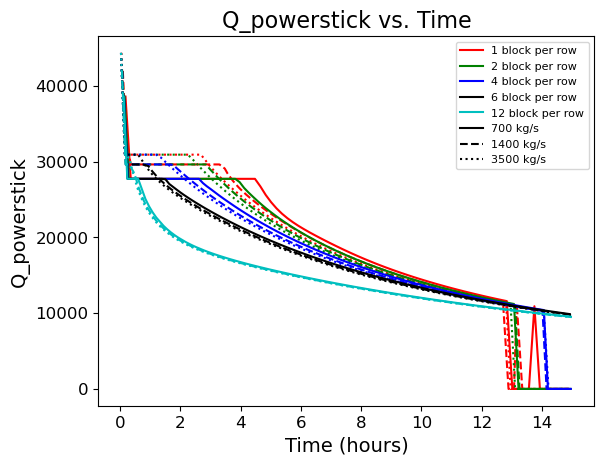

In [171]:
import re
with open("simulation_input_template.yaml", "r") as file:
    input_data = yaml.safe_load(file)
def process_results_matrix(results, end_time, target_state):
    time = np.array(results["time"]) / 3600  # Convert time to hours
    num_iterations = len(results["time"])
    # Extract data for plotting
    data_streams = {
        "time": time,
        "pump_power": np.array(results["pump_power"]),
        "heater_temp": np.array(results["heater_temp"]) - 273.15,
        "heater_power": np.array(results["heater_power"]) / 1000,  # Convert to kW
        "power_generated": np.array(results["power_generated"]) / 1000,  # Convert to kW
        "waste_heat": np.array(results["waste_heat"]) / 1000,  # Convert to kW
        "pipe_heat_loss": np.array(results["Pipe_heat_loss"]) / 1000,  # Convert to kW
        "Q_storage": np.array(results["Q_storage"]) / 1000,  # Convert to kW
        "Q_tin": np.array(results["Q_tin"]) / 1000,  # Convert to kW
        "Batt_level": np.array(results["batt_level"])
    }
    # Extract the temperature of the innermost radial, last axial step storage block cell
    data_streams["innermost_radial_last_axial_temp"] = np.array([results["storage_temp_dist"][iteration][-1, 0] for iteration in range(num_iterations)]) - 273.15
    # Calculate the average storage block temperature
    data_streams["average_storage_temp"] = np.array([np.mean(results["storage_temp_dist"][iteration]) for iteration in range(num_iterations)]) - 273.15
    # Calculate the integral of Q_storage with non-static iteration duration
    Q_block_full = V_storage * 500 * storage_cp(2448) * storage_rho(2448) / 3.6e9
    iter_full = np.where(np.array(results["batt_level"])/ Q_block_full > target_state)[0]
    if iter_full.size == 0: #battery doesn't reach threshhold
        #time_full = np.array(data_streams["time"])[-1]
        time_full = 0
    else:
        time_full = np.array(data_streams["time"])[iter_full[0]]
    print("batt charge time: ", time_full)
    iteration_durations = np.diff(np.array(results["time"]))
    #Q_block_init = Q_block_full #0 for charging, Q_block_full for discharging
    Q_block_init = 0
    iteration_durations = np.append(iteration_durations, end_time - results["time"][-1])
    data_streams["Q_storage_integral"] = (Q_block_init + np.cumsum(data_streams["Q_storage"] * iteration_durations)) / Q_block_full
    data_streams["Electricity_integral"] = np.cumsum(data_streams["power_generated"] * iteration_durations)
    data_streams["Batt_level"] = (Q_block_init  + data_streams["Batt_level"]) / Q_block_full

    return data_streams,time_full

def downsample_data(data_streams, num_points=100):
    indices = np.linspace(0, len(data_streams["time"]) - 1, num_points).astype(int)
    downsampled_streams = {}
    for key, value in data_streams.items():
        if isinstance(value, np.ndarray) and len(value) > 1:
            downsampled_streams[key] = value[indices]
        else:
            downsampled_streams[key] = value# Keep scalars or incompatible arrays as is
    return downsampled_streams

def generate_handles(vary_param, param_values, fixed_params):
    handles = []
    for val in param_values:
        # Find the matching result for the current param value
        for result in all_results:
            if precise_match(result["label"], {**fixed_params, vary_param: val}):
                handles.append(plt.Line2D([0], [0], linestyle=result["line_style"], color=result["color"], marker=result["shape"], markersize=result["size"], label=f'{vary_param}={val}'))
                break
        
    return handles

def precise_match(label, fixed_params):
    # Create a regex pattern to match the exact parameter values
    for k, v in fixed_params.items():
        pattern = rf"{k}={v},"
        if not re.search(pattern, label):
            return False
    return True
        
def plot_results(all_params, vary_param, file_suffix):
    fixed_params = {k: v for k, v in all_params.items() if k != vary_param}
    fixed_params_str = ', '.join([f"{k}={v}" for k, v in fixed_params.items()])
    #print(f"Fixed parameters: {fixed_params}")  # Debugging print statement
    plt.figure()
    first_entry = True
    for result in all_results:
        if precise_match(result["label"], fixed_params):
            #print(f"Matched result with label: {result['label']}")  # Debugging print statement for matches
            time = result["data_streams"]["time"]
            Batt_level = result["data_streams"]["Batt_level"]
            plt.plot(time, Batt_level, linestyle=result["line_style"], color=result["color"], marker=result["shape"],
                     markersize=result["size"], label=result["label"] if first_entry else "")
            first_entry = False

    # Adding legend for the varying parameter
    handles = generate_handles(vary_param, param_values, fixed_params)
    plt.legend(handles=handles, loc='best')

    plt.xlabel("Time (hours)")
    plt.ylabel("Battery Charge State")
    plt.title(f"Battery State: {fixed_params_str}")
    plt.savefig(os.path.join(new_folder, f'Battery_Charge_State_{file_suffix}.png'))

    plt.figure()
    first_entry = True
    for result in all_results:
        if precise_match(result["label"], fixed_params):
            print(f"Matched result with label: {result['label']}")  # Debugging print statement for matches
            time = result["data_streams"]["time"]
            Q_powerstick = result["data_streams"]["power_generated"] + result["data_streams"]["waste_heat"]
            plt.plot(time, Q_powerstick, linestyle=result["line_style"], color=result["color"], marker=result["shape"], 
                     markersize=result["size"], label=result["label"] if first_entry else "")
            first_entry = False

    plt.legend(handles=handles, loc='best')
    plt.xlabel("Time (hours)")
    plt.ylabel("Q_powerstick")
    plt.title("Q_powerstick vs. Time")
    plt.savefig(os.path.join(new_folder, f'Q_powerstick_{file_suffix}.png'))

def plot_battery_full_times(time_full, heating_rates, num_storage_blocks, block_in_rads, output_folder):
    """
    Plot the times at which the battery becomes full for each condition, grouped by heating rate,
    excluding points where the value is 0.

    Parameters:
        time_full (numpy.ndarray): Array of times at which the battery becomes full (indexed by heating rate and block in radius).
        heating_rates (list): List of heating rates.
        block_in_rads (list): List of block in radii.
        output_folder (str): Folder to save the output plot.
    """
    plt.figure()
    
    
    # Loop through each heating rate and plot the corresponding times
    for i, heating_rate in enumerate(heating_rates):
        for j, num_blocks in enumerate(num_storage_blocks):
        # Get the times and radii for the current heating rate
            #times = time_full[i, :, j, 0, 0]
            times = time_full[i,j]
            print(heating_rate, num_blocks,times)
            area_ratios = np.array(block_in_rads) / (0.5 * input_data["storage"]["Pipe"]["OD"])
            
            # Filter out points where time is 0
            valid_indices = times > 0
            filtered_times = times[valid_indices]
            filtered_AR = np.array(area_ratios)[valid_indices]
            
            # Plot the filtered data
            plt.plot(filtered_AR, filtered_times, label=f'HR={heating_rate}, SB={num_blocks}', marker='o', linestyle=linestyles[j], color=colors[i] )
    
    plt.xlabel("Area Ratio")
    plt.ylabel("Time to Full Battery (hours)")
    plt.title("Time to Full Battery vs. Area Ratio")
    plt.legend(fontsize=8,loc='best')
    plt.grid(True)
    
    # Save the plot
    plt.savefig(os.path.join(output_folder, 'Time_to_Full_Battery.png'))
    print(f"Plot saved as 'Time_to_Full_Battery.png' in {output_folder}")
    
# Initialize arrays to store results
all_labels = []
all_results = []
time_full = np.empty_like(results)
target_state = 0.98 #threshhold battery level

# Directory containing the results files
results_dir = new_folder
# Define the symbol shapes, sizes, and colors
shapes = ['o', 's', '^']  # Circle, square, and triangle for powerstick lengths
linestyles = ['-', '--', ':', '-.']
sizes = [8, 12, 15]  # Different sizes for block numbers
colors = ['r', 'g', 'b', 'k', 'c']  # Red, green, and blue for heating rates

for i, blocks_per_row in enumerate(num_blocks_per_row):
#for i, heating_rate in enumerate(heating_rates):
    #for j, block_in_rad in enumerate(block_in_rads):
    for j, flow_rate_val in enumerate(flow_rate_vals):
        #for k, num_blocks in enumerate(num_storage_blocks):
            #for m, bypass_bool in enumerate(bypass_bools):
                #for n, flow_rate_val in enumerate(flow_rate_vals):
        #file_name = f"input_hr{heating_rate}_pl{powerstick_length}_sb{num_blocks}_bp{bypass_bool}_fr{flow_rate_val}.yaml"
        file_name = f"HR{heating_rate}_FR{flow_rate_val}_SB{blocks_per_row}.yaml"
        file_path = os.path.join(results_dir, file_name)
        
        # Load and process the results
        result = results[i, j]
        data_streams,time_full[i, j] = process_results_matrix(result, end_time, target_state)
        
        # Downsample the data to 10 points
        data_streams = downsample_data(data_streams)
        
        # Store the results
        all_results.append({
            "data_streams": data_streams,
            #"label": f"TL={T_emitter_lim},HR={heating_rate}, PL={powerstick_length}, SB={num_blocks}, BP={bypass_bool}, FR={flow_rate_val},",
            "label": f"HR={heating_rate}, FR={flow_rate_val}, SB={blocks_per_row}",
            #"shape": shapes[j],
            "line_style": linestyles[j],
            "color": colors[i],
            #"size": sizes[m]
        })
        print(f"HR={heating_rate}, FR={flow_rate_val}, SB={blocks_per_row}")
block_in_rad = [0.12]
num_rows_arr = [tot_num_blocks / bpr for bpr in num_blocks_per_row]
print(num_rows_arr)
#plot_battery_full_times(time_full, heating_rates, num_rows_arr,block_in_rad, new_folder)                  

# Define all parameters
all_params = {
    "HR": 1,  # Default value, will be varied in the loop
    #"RI": 0.12,
    #"PL": 3,
    "SB": 6,
    "FR": 7000.0,
    #"BP": True,
    #"TL": 2523,
    #"GDE": 0.05
}

# Vary each parameter and plot results
#for vary_param, param_values in [("TL", T_emitter_lims),("BP", bypass_bools), ("HR", heating_rates), ("SB", num_storage_blocks), ("FR", flow_rate_vals)]:
for vary_param, param_values in [("SB", num_blocks_per_row), ("FR", flow_rate_vals)]:
    plot_results(all_params, vary_param, f"{vary_param}_varied")

# Plot Q_storage_integral vs. time for each case
plt.figure()
first_entry = True
for result in all_results:
    time = result["data_streams"]["time"]
    Q_storage_integral = result["data_streams"]["Q_storage_integral"]
    Batt_level = result["data_streams"]["Batt_level"]
    plt.plot(time, Batt_level, linestyle=result["line_style"], color=result["color"], label=result["label"] if first_entry else "")
    first_entry = False
# Adding legend for the symbols
handles = [
    plt.Line2D([0], [0], linestyle='-', color='r', label='1 block per row'),
    plt.Line2D([0], [0], linestyle='-', color='g', label='2 block per row'),
    plt.Line2D([0], [0], linestyle='-', color='b', label='4 block per row'),
    plt.Line2D([0], [0], linestyle='-', color='k', label='6 block per row'),
    plt.Line2D([0], [0], linestyle='-', color='c', label='12 block per row'),
    plt.Line2D([0], [0], linestyle='-', color='k', label='700 kg/s'),
    plt.Line2D([0], [0], linestyle='--', color='k', label='1400 kg/s'),
    plt.Line2D([0], [0], linestyle=':', color='k', label='3500 kg/s'),   
    #plt.Line2D([0], [0], linestyle='-', color='g', label='0.1 GD emissivity'),
    #plt.Line2D([0], [0], linestyle='-', color='b', label='0.2 GD emissivity'),
    #plt.Line2D([0], [0], linestyle='-', color='k', label='0.4 GD emissivity'),
    #plt.Line2D([0], [0], linestyle='-', color='c', label='0.8 GD emissivity')
]
plt.legend(handles=handles, loc='best')
plt.xlabel("Time (hours)")
plt.ylabel("Battery Charge State")
plt.title("Battery Charge State vs. Time")
#plt.show()
plt.savefig(os.path.join(new_folder, 'Battery Charge State.png'))

plt.figure()
first_entry = True
for result in all_results:
    time = result["data_streams"]["time"]
    Q_powerstick = result["data_streams"]["power_generated"] + result["data_streams"]["waste_heat"]
    #plt.plot(time, Q_powerstick, linestyle=result["line_style"], color=result["color"], marker=result["shape"], label=result["label"] if first_entry else "")
    plt.plot(time, Q_powerstick, linestyle=result["line_style"], color=result["color"], label=result["label"] if first_entry else "")
    first_entry = False

plt.legend(fontsize=8,handles=handles, loc='best')
plt.xlabel("Time (hours)")
plt.ylabel("Q_powerstick")
plt.title("Q_powerstick vs. Time")
#plt.show()
plt.savefig(os.path.join(new_folder, 'Q_powerstick.png'))

Scratchwork cells to test modules of code

In [ ]:
def calculate_stored_energy(temp_dist_1: np.ndarray, temp_dist_2: np.ndarray, block: GraphiteBlock, num_rad_segments: int, num_ax_segments: int) -> float:
    """
    Calculate the total stored energy in the storage block given a temperature distribution.
    
    Parameters:
    temp_dist (2D array): Temperature distribution in the block (K).
    block (GraphiteBlock): GraphiteBlock object representing the physical properties of the storage block.
    num_rad_segments (int): Number of radial segments in the storage block.
    num_ax_segments (int): Number of axial segments in the storage block.
    
    Returns:
    float: Total stored energy in the storage block (J).
    """
    r_inner = block.rad_in
    r_outer = block.rad_out
    dr = (r_outer - r_inner) / num_rad_segments
    dz = block.length / num_ax_segments
    total_energy = 0.0
    
    for i in range(num_ax_segments):
        for j in range(num_rad_segments):
            r_in = r_inner + j * dr
            r_out = r_in + dr
            volume = np.pi * (r_out ** 2 - r_in ** 2) * dz
            dT = temp_dist_2[i,j] - temp_dist_1[i, j]
            energy_density = storage_cp(temp_dist_2[i,j]) * storage_rho(temp_dist_2[i,j]) * dT
            total_energy += energy_density * volume
    
    return total_energy
    
pipe1=Pipe(.058,3, .00635, 1e-6,0.0)
temp=2722
mu=Sn_mu(temp)
tcx=Sn_tcx(temp)
Q_in=0
N_pipes=10
HM1=HeatingModule(Q_in,N_pipes,pipe1)
T_in=2710
P_in=1e6
mdot=.5
fluid_pipe = Fluid(T_in, P_in, mdot)
print(HM1.heat_input)
heater_temp, T_pipe_outer, T_pipe_inner  = HM1.solve_heater_temperature(fluid_pipe)

print(f"Solved heater temperature: {heater_temp:.2f} K")
print(f"Pipe outer wall temperature: {T_pipe_outer:.2f} K")
print(f"Pipe inner wall temperature: {T_pipe_inner:.2f} K")
fluid_heat_out = HM1.outlet_condition(fluid_pipe)
print(f"heater outlet temperature: {fluid_heat_out.temperature:.2f} K")
print(f"heater outlet pressure: {fluid_heat_out.pressure:.2f} Pa")

num_ax_segments = 20
num_rad_segments = 10
N_blocks = 16
time_step = 100
pipe2=Pipe(.05,2, .005, 1e-5,0)
init_block_temp_dist = np.full((num_ax_segments, num_rad_segments), 2600)
GB1 = GraphiteBlock(init_block_temp_dist, 0.1, 0.225, pipe2.length)
SM1 = StorageModule(N_blocks,pipe2,GB1,num_ax_segments, num_rad_segments)
#print("test Q: ", SM1.heat_transfer_rate(fluid_heat_out, 2500))
print(GB1.temp_dist)
#Q_stored_init = calculate_stored_energy(GB1.temp_dist, GB1, num_rad_segments, num_ax_segments)
fluid_store_out, Q_total,Q_rad, T_tin = SM1.outlet_conditions(fluid_heat_out)
print(f"Tin temperatures along the length: {T_tin}")
print(f"storage outlet pressure: {fluid_store_out.pressure:.2f} Pa")
print(f"Total heat transferred to blocks: {Q_total:.2f} W")
print("Heat flux distribution:")
print(Q_rad)
new_temp_dist = SM1.update_temps(GB1.temp_dist, Q_rad, time_step)
Q_stored = calculate_stored_energy(init_block_temp_dist, new_temp_dist, GB1, num_rad_segments, num_ax_segments)
W_store = Q_stored / time_step * N_blocks
print("W_store: ", W_store, "Q_total_tin: ", Q_total)
print(new_temp_dist)
#time_step = 500 #[s]
#for i in range(0,20):
    #SM1.update_temps(init_block_temp_dist, Q_rad, time_step)
#    GB1.temp_dist = SM1.update_temps(GB1.temp_dist, Q_rad, time_step)
#    fluid_store_out, Q_total,Q_rad, T_tin = SM1.outlet_conditions(fluid_heat_out)
#    print("Updated temperature distribution:")
#    print(GB1.temp_dist)
#    print(f"Tin temperatures along the length: {T_tin}")
#    print(f"Total heat transferred to blocks: {Q_total:.2f} W")
#    print("Heat flux distribution:")
#    print(Q_rad)


In [129]:
emissivity_table = [
        ((0.1, 1.0), 0.95, 0.05, 0.02),  # Below 1 micron
        ((1.0, 20.0), 0.1, 0.05, 0.02)  # Above 1 micron
    ]
f_bare = 0.25
f_active = 0.85
N_cells = 1
T_tin_in = 2673  # K
P_tin_in = 1013250 #Pa
mdot = 1000  # kg/s
panel_efficiency = 0.5
axial_steps = 4
pipe_height = 0.01
emitter_width = 0.4
length = 3.0
pipe_roughness=1e-6
powerstick_width = 0.1
wall_thickness = 0.005
cooling_temp = 313
T_tin_max_PCB = 2473
fluid_PCB_in = Fluid(T_tin_in, P_tin_in, mdot)
PCB1=PowerConversionBlock(axial_steps, N_cells, pipe_height, emitter_width, length, pipe_roughness, 
                          powerstick_width,wall_thickness, cooling_temp, panel_efficiency, T_tin_max_PCB, f_bare, f_active, emissivity_table)
print(PCB1.powerstick.emissivity_table)
temperatures, electricity_generated, waste_heat = PCB1.power_conversion(fluid_PCB_in)
    
print("Temperatures:", temperatures)
print("Electricity Generated:", electricity_generated)
print("Waste Heat:", waste_heat)
cProfile.run('PCB1.determine_outlet_conditions(fluid_PCB_in)')
fluid_PCB_out = PCB1.determine_outlet_conditions(fluid_PCB_in)
print("Outlet Temperature:", fluid_PCB_out.temperature)
print("Outlet Pressure:", fluid_PCB_out.pressure)

pump1 = Pump(0.8)
power = 1e4
T_pump_in = 2000
P_pump_in = 1e6
mdot_pump = 20
fluid_pump_in = Fluid(T_pump_in, P_pump_in, mdot_pump)
fluid_pump_out = pump1.outlet_conditions(power, fluid_pump_in)
print("Outlet Temperature:", fluid_pump_out.temperature)
print("Outlet Pressure:", fluid_pump_out.pressure)
pump_power, fluid_pump_out2 = pump1.required_power(fluid_pump_in, fluid_pump_out.pressure)
print("Outlet Temperature:", fluid_pump_out2.temperature)
print("Required Power:", pump_power)

[((0.1, 1.0), 0.95, 0.05, 0.02), ((1.0, 20.0), 0.1, 0.05, 0.02)]
Temperatures: [2673.         2672.83442862 2672.66891973 2672.5034733  2672.33808929]
Electricity Generated: 96179.45314553622
Waste Heat: 117345.39638638738
         70634 function calls (70630 primitive calls) in 0.139 seconds

   Ordered by: standard name

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
        4    0.000    0.000    0.105    0.026 1757374007.py:484(calculate_temperatures)
       60    0.000    0.000    0.000    0.000 1757374007.py:506(<genexpr>)
        1    0.000    0.000    0.039    0.039 1757374007.py:527(power_conversion)
        1    0.000    0.000    0.049    0.049 1757374007.py:570(determine_outlet_conditions)
       25    0.000    0.000    0.000    0.000 1818119203.py:1(Sn_rho)
       12    0.000    0.000    0.000    0.000 1818119203.py:101(gr_tcx)
       16    0.000    0.000    0.000    0.000 1818119203.py:13(Sn_cp)
       12    0.000    0.000    0.000    0.000 1818119

plotting

In [140]:
def create_new_folder(base_folder='plots', label='plot'):
    """Creates a new folder with an incremented number in the base folder."""
    if not os.path.exists(base_folder):
        os.makedirs(base_folder)
    
    # Get the list of existing folders
    existing_folders = [f for f in os.listdir(base_folder) if os.path.isdir(os.path.join(base_folder, f))]
    
    # Extract numbers from folder names
    existing_numbers = [int(folder.split('_')[-1]) for folder in existing_folders if folder.startswith('plot_')]
    
    # Determine the new folder number
    new_number = max(existing_numbers, default=0) + 1
    
    # Create the new folder
    new_folder = os.path.join(base_folder, f'{label}_{new_number}')
    os.makedirs(new_folder)
    
    return new_folder

In [324]:
time_full[0,:,0,0,0]

array([12.115277777777777, 11.085, 10.224444444444444, None, None, None,
       None], dtype=object)

In [3]:
T= 2673
print(gr_rho(T),gr_cp(T),gr_tcx(T))
print(storage_rho(T),storage_cp(T),storage_tcx(T))
print(Sn_rho(T),Sn_cp(T),Sn_tcx(T), Sn_mu(T))

1860 2168.2189764086925 51.5
1450 2000 15
5623.4933388339205 300 90.56164000000001 0.0005253190916264639


In [11]:
gr_emis(2373)

0.82138

In [ ]:
Sn_mu(2273)

17.5/(5623.5*12*np.pi*.0127**2)